# Geatomatiseerde Stroke-Risico Classificatie 
### MedPredict Analytics - Machine Learing

**Groep:** Groep 7 (RSR)

**Teamleden:** 
- Resham Anwar (25141511)
- Sharina Nasrullah (25103083)
- Rishano Narraina (25113011)

**Kaggle Usernames:** 
- Resham Anwar 
- SharinaHHS


## Inleiding

MedPredict is een medisch technologiebedrijf dat ziekenhuizen en zorginstellingen ondersteunt bij het vroegtijdig herkennen van gezondheidsrisico’s door middel van datagedreven analyse en voorspellende modellen. Binnen deze context beschikt MedPredict over een uitgebreide verzameling geanonimiseerde patiëntgegevens, waaronder demografische kenmerken, leefstijlfactoren en medische informatie.

Een belangrijke uitdaging is het tijdig identificeren van patiënten met een verhoogd risico op een herseninfarct (stroke). Vroege detectie kan bijdragen aan gerichte preventie en betere opvolging.

Ons team van junior data scientists heeft de opdracht gekregen om een machine-learningmodel te ontwikkelen dat voorspelt of een patiënt een herseninfarct heeft gehad.

Om verschillende oplossingen te vergelijken, organiseert MedPredict een interne data-sciencecompetitie via Kaggle. Teams van de opleiding Applied Data Science & AI strijden om het best presterende model. Hierbij telt niet alleen de uiteindelijke score, maar ook de zorgvuldigheid van de gemaakte keuzes. Het winnende team ontvangt 5 bonuspunten boven op het reguliere cijfer.

## Probleemstelling

MedPredict heeft behoefte aan een betrouwbaar automatisch voorspellingssysteem dat:

- het risico op een herseninfarct zo nauwkeurig mogelijk kan voorspellen;
- foutieve voorspellingen zoveel mogelijk beperkt, vanwege de mogelijke medische impact;
- zorgprofessionals kan ondersteunen bij vroegtijdige risicodetectie en preventie.

## Libraries importeren

In [74]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## De datasets

Voor deze opdracht heeft MedPredict drie datasets beschikbaar gesteld: `train.csv`, `test.csv` en `sample_submission.csv`

* train.csv - bevat alle patiëntgegevens en de doelvariabele.
* test.csv - bevat dezelfde kenmerken maar zonder de doelvariabele; deze wordt gebruikt om voorspellingen te genereren voor Kaggle
* sample_submission.csv - een voorbeeldbestand dat het vereiste Kaggle‑indieningsformaat toont.

In [75]:
train= pd.read_csv("train.csv")
test= pd.read_csv("test.csv")
sample= pd.read_csv("sample_submission.csv")

## 1. Data begrijpen & Exploratieve Data Analyse 

In deze fase onderzoeken we de structuur en kwaliteit van de dataset. Daarnaast bekijken we welke variabelen mogelijk samenhangen met de doelvariabele `stroke`.

### 1.1 beschrijving van de kolommen

De dataset bevat verschillende demografische, medische en leefstijlvariabelen.
Onderstaande tabel geeft een overzicht van alle variabelen.

| kolom | uitleg | type |
|-------|-------|------|
| id    | unieke identificatie van de patiënt | numeriek |
| age   | leeftijd van de patiënt | numeriek |
| hypertension | Geeft aan of de patiënt hypertensie (hoge bloeddruk) heeft. 0 = nee, 1 = ja | numeriek (binair) |
| heart_disease | Geeft aan of de patiënt hartaandoening heeft: 0 = nee, 1 = ja | numeriek (binair) |
| avg_glucose_level| gemiddelde glucosegehalte van de patiënt | numeriek |
| bmi | Body Mass Index van de patiënt| numeriek |
| gender_Female | geeft aan of de patiënt een vrouw is. False = nee, True = ja | numeriek (binair) |
| gender_Male | geeft aan of de patiënt een man is. False = nee, True = ja | numeriek (binair) |
| gender_Other | geeft aan of de patiënt onder de categorie "other" valt. False = nee, True = ja | numeriek (binair) |
| ever_married_No | geeft aan of de patiënt nooit is getrouwd. False = nee, True = ja | numeriek (binair) |
| ever_married_Yes | geeft aan of de patiënt ooit is getrouwd. False = nee, True = ja | numeriek (binair) |
| work_type_Govt_job | geeft aan of de patiënt een overheidsbaan heeft. False = nee, True = ja | numeriek (binair) |
| work_type_Never_worked | geeft aan of de patiënt nooit heeft gewerkt. False = nee, True = ja | numeriek (binair) |
| work_type_Private | geeft aan of de patiënt in de private sector heeft gewerkt. False = nee, True = ja | numeriek (binair) |
| work_type_Self-employed | geeft aan of de patiënt zelfstandig ondernemer is. False = nee, True = ja | numeriek (binair) |
| work_type_children | geeft aan of de patiënt een kind is of niet. False= geen kind, True= wel kind | numeriek (binair) |                                            
| Residence_type_Rural | geeft aan of de patiënt in een landelijke gebied woont. False = nee, True = ja | numeriek (binair) |
| Residence_type_Urban | geeft aan of de patiënt in een stedelijke gebied woont. False = nee, True = ja | numeriek (binair) |
| smoking_status_formerly smoked | geeft aan of de patiënt vroeger rookte. False = nee, True = ja | numeriek (binair) |
| smoking_status_never smoked | geeft aan dat de patiënt nooit heeft gerookt. False = nee, True = ja | numeriek (binair) |
| smoking_status_smokes | geeft aan dat de patiënt rookt. False = nee, True = ja | numeriek (binair) |
| stroke | doelvariabele. geeft aan of de patiënt een stroke heeft gehad | numeriek (binair) |

### 1.2 Data exploren

In deze stap controleren we de dataset op eigenschappen die belangrijk zijn voor machine learning. We kijken onder andere naar:

- het aantal observaties en variabelen;
- datatypes;
- ontbrekende waarden;
- dubbele rijen;
- beschrijvende statistieken.

In [76]:
print("Datasetinformatie:")
train.info()

print("\nOntbrekende waarden:")
print(train.isna().sum())

print("\nAantal dubbele rijen:", train.duplicated().sum())

print("\nBeschrijvende statistieken:")
display(train.describe())

Datasetinformatie:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 33550 entries, 0 to 33549
Data columns (total 22 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              33550 non-null  int64  
 1   age                             33550 non-null  float64
 2   hypertension                    33550 non-null  int64  
 3   heart_disease                   33550 non-null  int64  
 4   avg_glucose_level               33550 non-null  float64
 5   bmi                             33550 non-null  float64
 6   gender_Female                   33550 non-null  bool   
 7   gender_Male                     33550 non-null  bool   
 8   gender_Other                    33550 non-null  bool   
 9   ever_married_No                 33550 non-null  bool   
 10  ever_married_Yes                33550 non-null  bool   
 11  work_type_Govt_job              33550 non-null  bool   
 12  work_type_Nev

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000,33550.000000
mean,36746.393353,41.815312,0.088137,0.043040,103.587081,28.601216,0.015410
std,20906.519131,22.477423,0.283498,0.202951,42.127396,7.782248,0.123178
min,1.000000,0.080000,0.000000,0.000000,55.010000,10.100000,0.000000
25%,18763.250000,24.000000,0.000000,0.000000,77.460000,23.300000,0.000000
50%,36862.000000,43.000000,0.000000,0.000000,91.320000,27.700000,0.000000
75%,54757.500000,59.000000,0.000000,0.000000,111.437500,32.800000,0.000000
max,72943.000000,82.000000,1.000000,1.000000,281.590000,97.600000,1.000000


De dataset voldoet grotendeels aan de minimale vereisten om gebruik te kunnen worden voor Machine Learning met Scikit-learn. De dataset bevat voldoende observaties en de variabelen zijn numeriek. De categorische variabelen zijn al omgezet naar dummy-variabelen, waardoor deze direct door de meeste Scikit-learn-modellen kunnen worden gebruikt.

De kolom 'stroke' wordt als target variabele gebruikt. 

Tijdens de data-analyse is ook gekeken naar multicollineariteit tussen de onafhankelijke variabelen. Hierbij bleek dat bij veel van de dummyvariabelen er een sterke samenhang lag. Om te voorkomen dat dit de Machine Learning-modellen negatief beïnvloedt, zijn de kolommen 'gender_Male', 'ever_married_No', 'Residence_type_Urban', 'work_type_Private', 'smoking_status_formerly smoked' verwijderd.

Daarnaast wordt de dataset gecontroleerd op ontbrekende waarden en dubbele rijen. Eventuele ontbrekende of problematische waarden worden aangepast voordat de modellen worden getraind.

Na deze controles, het verwijderen van id en het verwijderen van de variabelen met sterke multicollineariteit is de dataset geschikt om te gebruiken voor de verdere Machine Learning-analyse.

### 1.3 Targetvariabele, voorspellers & Data opschonen

Omdat meerdere categorische variabelen zijn omgezet naar dummyvariabelen, onderzoeken we of er sterke correlaties tussen deze variabelen aanwezig zijn

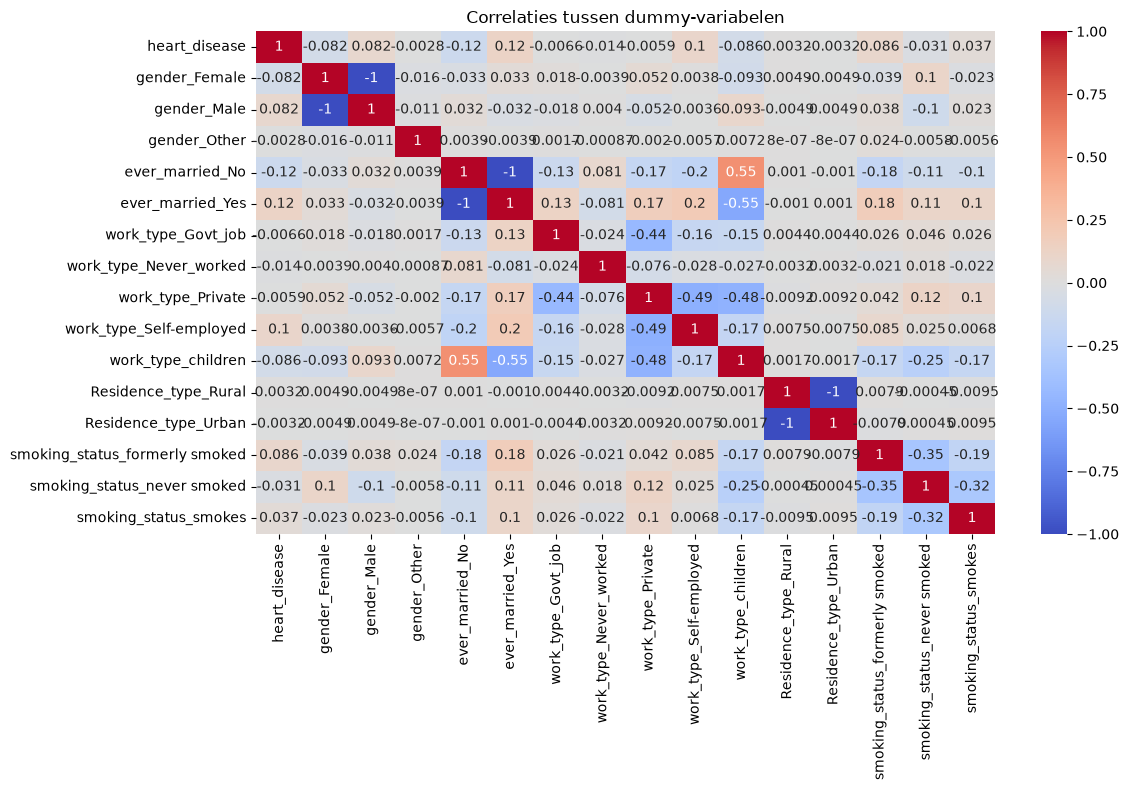

In [77]:
dummy_cols = [
    col for col in train.columns 
    if "_" in col and col not in ["avg_glucose_level", "bmi"]
]

plt.figure(figsize=(12, 8))
sns.heatmap(
    train[dummy_cols].corr(), 
    annot=True, 
    cmap="coolwarm", 
    center=0)

plt.title("Correlaties tussen dummy-variabelen")
plt.tight_layout()
plt.show()



**Conclusie**

Uit de correlatiematrix blijkt dat dummyvariabelen binnen dezelfde categorie, zoals `gender`, `work_type`, `smoking_status` en `Residence_type`, zeer sterke negatieve correlaties kunnen vertonen.

Dit komt doordat meerdere dummyvariabelen samen één oorspronkelijke categorie representeren. Om perfecte multicollineariteit te voorkomen, worden de overbodige dummyvariabelen verwijderd.

In [78]:
train= train.drop(columns= ['gender_Male', 'ever_married_No', 'Residence_type_Urban', 'work_type_Private', 'smoking_status_formerly smoked'])

X = train.drop(columns="stroke")
y = train["stroke"]


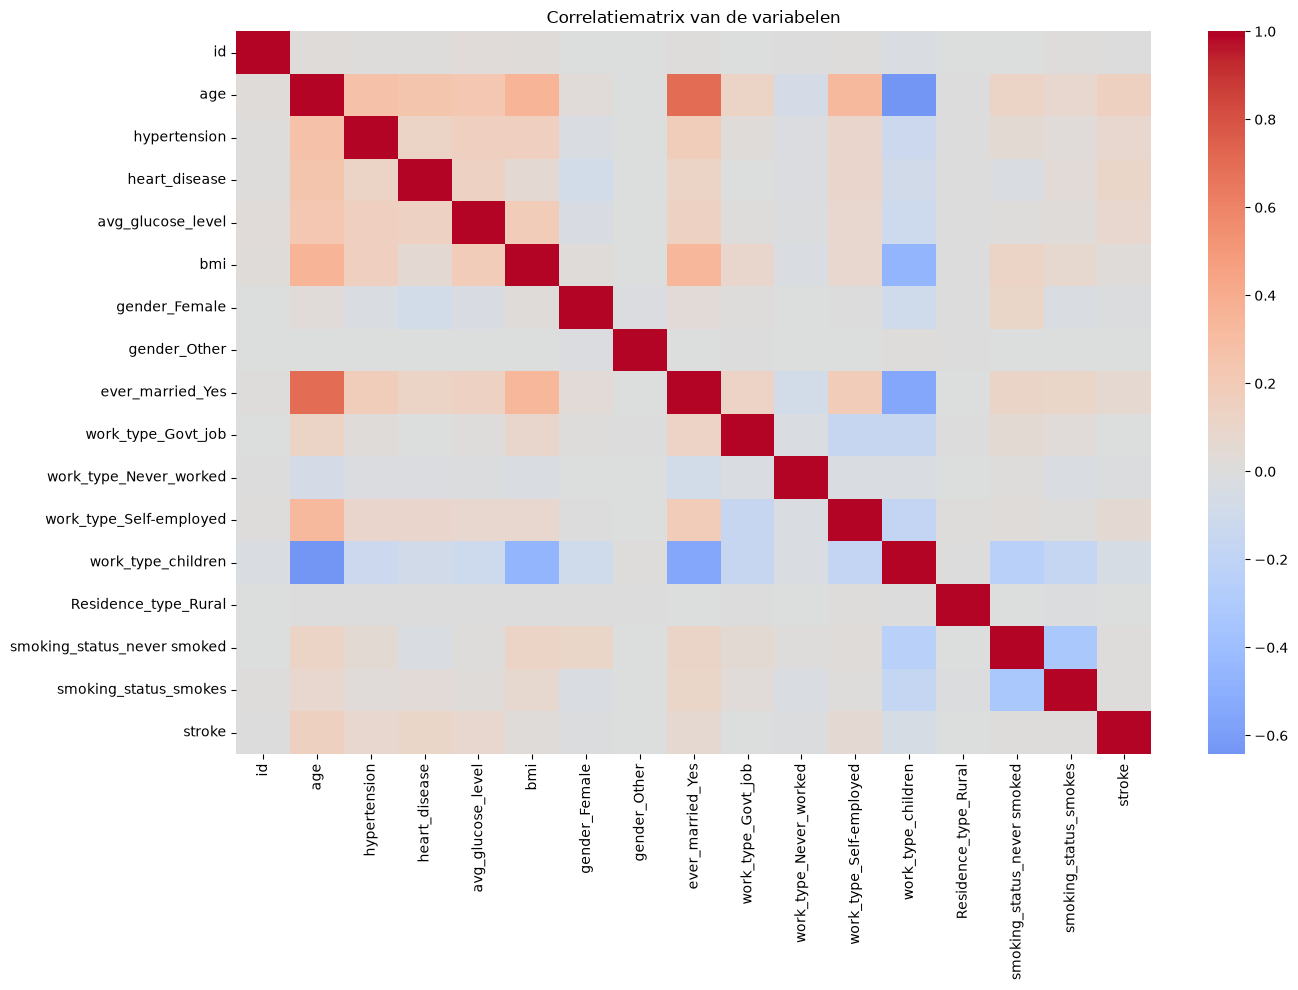

In [79]:
plt.figure(figsize=(14, 10))
sns.heatmap(
    train.corr(), 
    cmap="coolwarm", 
    center=0)

plt.title("Correlatiematrix van de variabelen")
plt.tight_layout()
plt.show()

In [80]:
categorical_cols = X.select_dtypes(include=['object', 'category']).columns
numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

print("Categorische kolommen:", list(categorical_cols))
print("Numerieke kolommen:", list(numerical_cols))

Categorische kolommen: []
Numerieke kolommen: ['id', 'age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']


**Verdeling van de targetvariabele:**

De doelvariabele `stroke` geeft aan of een patiënt een beroerte heeft gehad. We bekijken de verdeling om te bepalen of de dataset in balans is.

In [81]:
y.value_counts(normalize=True)

stroke
0    0.98459
1    0.01541
Name: proportion, dtype: float64

Hier kunnen we zien dat de dataset sterk ongebalanceerd is.
0.98% van de uitkomsten zijn 0, oftewel geen stroke, in vergelijking met de uitkomst 1, die 0.01% voorkomt als uitkomst.

### 1.4 Relaties tussen variabelen en stroke

We onderzoeken verschillende variabelen afzonderlijk om te bekijken of er zichtbare verschillen zijn tussen patiënten met en zonder stroke.

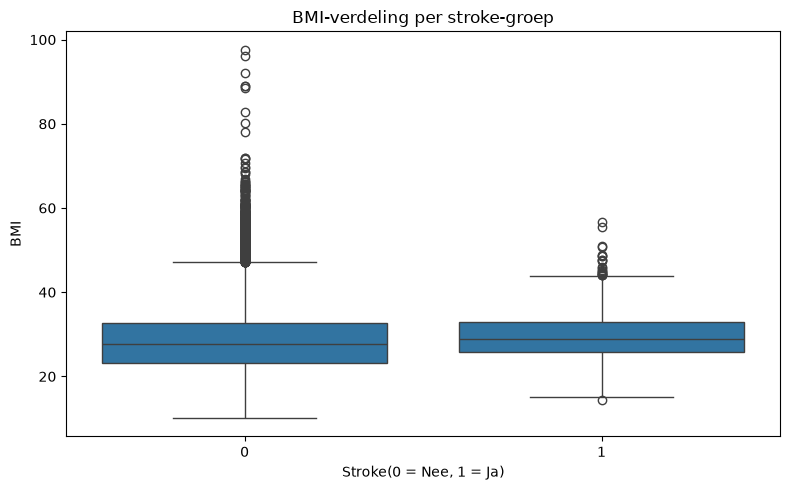

In [82]:
plt.figure(figsize=(8, 5))
sns.boxplot(
    data= train, 
    x='stroke', 
    y= 'bmi')

plt.title("BMI-verdeling per stroke-groep")
plt.xlabel("Stroke(0 = Nee, 1 = Ja)")
plt.ylabel("BMI")

plt.tight_layout()
plt.show()

**Conclusie**

De boxplot toont de verdeling van BMI voor personen met en zonder beroerte. De mediane BMI‑waarden liggen dicht bij elkaar en de interkwartielafstanden overlappen volledig. Dit wijst erop dat BMI geen duidelijke verschillen vertoont tussen de stroke‑ en niet‑stroke‑groep. Hoewel er enkele outliers aanwezig zijn, komen deze in beide groepen voor. Op basis van deze visualisatie lijkt BMI geen sterke relatie te hebben met het optreden van een beroerte.

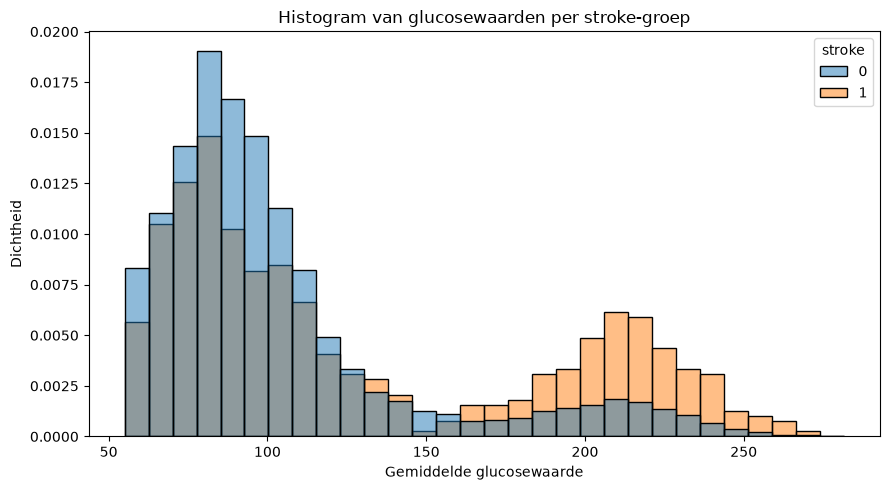

In [83]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=train, 
    x='avg_glucose_level', 
    hue='stroke',  
    bins= 30, 
    stat= "density", 
    common_norm= False )

plt.title("Histogram van glucosewaarden per stroke-groep")
plt.xlabel("Gemiddelde glucosewaarde")
plt.ylabel("Dichtheid")

plt.tight_layout()
plt.show()

**Conclusie**


De verdelingen van `avg_glucose_level` voor de stroke- en niet-strokegroep overlappen gedeeltelijk. Omdat de dataset sterk ongebalanceerd is, is gebruikgemaakt van een densityplot. Hierdoor kunnen de vormen van beide verdelingen beter met elkaar worden vergeleken.

De visualisatie laat zien dat er verschillen zijn tussen beide groepen, maar dat de verdelingen niet volledig van elkaar gescheiden zijn. De niet‑stroke‑groep heeft glucosewaarden tussen 50 en 160, terwijl de stroke‑groep geconcentreerd is rond de waarden 130 - 280. 
De verdelingen overlappen slechts minimaal, wat wijst op een sterke relatie tussen hogere glucosewaarden en het optreden van een beroerte.

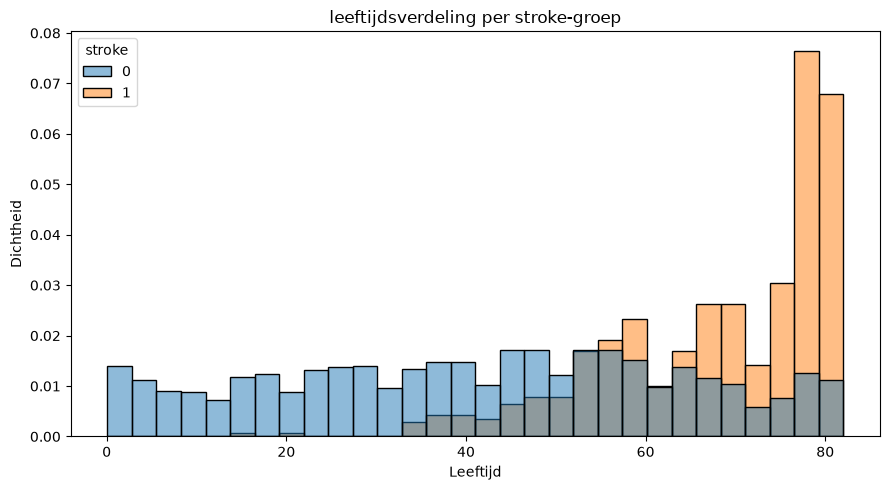

In [84]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=train, 
    x='age', 
    hue='stroke', 
    bins= 30, 
    stat= "density", 
    common_norm= False)

plt.title("leeftijdsverdeling per stroke-groep")
plt.xlabel("Leeftijd")
plt.ylabel("Dichtheid")

plt.tight_layout()
plt.show()

**Conclusie**

 De densityplot laat een duidelijke relatie zien tussen leeftijd en het optreden van een beroerte. De stroke-groep is sterk geconcentreerd bij hogere leeftijden (60-80 jaar), terwijl de niet-stroke groep breder verdeeld is over jongere leeftijden (0-50 jaar). Omdat de dataset ongebalanceerd is, is gebruikgemaakt van een densityplot, waardoor de vorm van beide verdelingen zichtbaar blijft. De verdelingen overlappen slechts beperkt. Dit wijst erop dat leeftijd een belangrijke variabele kan zijn voor het voorspellen van stroke.

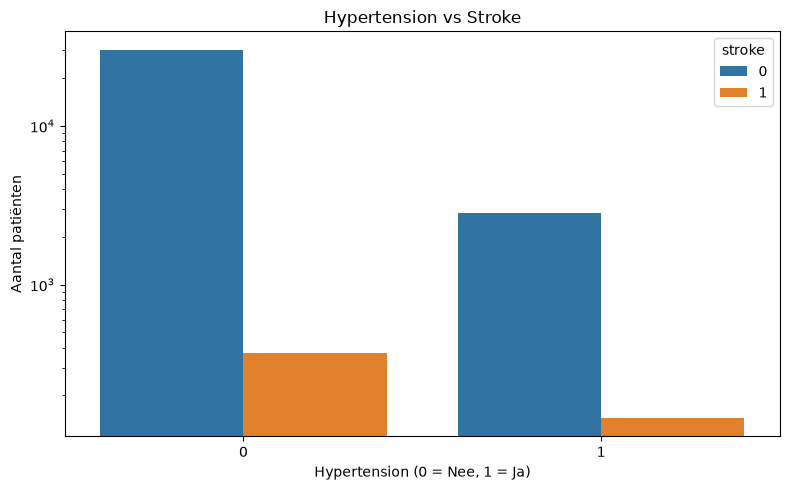

In [85]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=train, 
    x="hypertension", 
    hue="stroke")

plt.title("Hypertension vs Stroke")
plt.xlabel("Hypertension (0 = Nee, 1 = Ja)")
plt.ylabel("Aantal patiënten")
plt.yscale("log")

plt.tight_layout()
plt.show()

**Conclusie**

De countplot toont de relatie tussen hypertension en stroke. Omdat de dataset sterk ongebalanceerd is, is een logaritmische y‑as gebruikt om de kleinere stroke‑groep beter zichtbaar te maken. 

Uit de visualisatie blijkt dat personen met hypertension relatief vaker een stroke hebben dan personen zonder hypertension. Dit wijst op een duidelijke relatie tussen hoge bloeddruk en het optreden van een stroke.

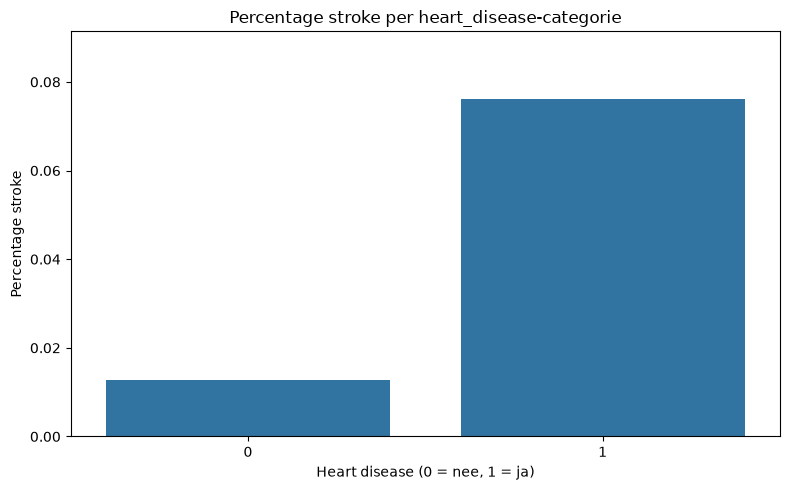

In [86]:
percentages = (
    train.groupby("heart_disease")["stroke"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=percentages, 
    x="heart_disease", 
    y="stroke")


plt.title("Percentage stroke per heart_disease-categorie")
plt.xlabel("Heart disease (0 = nee, 1 = ja)")
plt.ylabel("Percentage stroke")
plt.ylim(0, percentages["stroke"].max() * 1.2)

plt.tight_layout()
plt.show()

**Conclusie**

De percentage‑barplot laat zien welk deel van de personen binnen elke heart_disease‑categorie een stroke heeft gehad. 

Omdat zowel heart_disease als stroke binaire variabelen zijn, is een percentageplot geschikt om de groepen met elkaar te vergelijken. De visualisatie laat zien dat personen met hartziekte relatief vaker een stroke hebben gehad. 
Dit wijst op een duidelijke relatie tussen hartziekte en het optreden van een stroke.

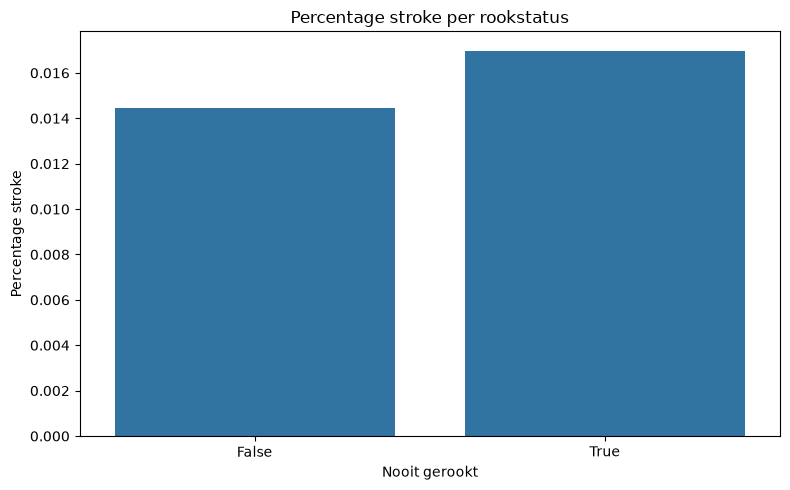

In [87]:
percent_smoking = (
    train.groupby("smoking_status_never smoked")["stroke"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=percent_smoking, 
    x="smoking_status_never smoked", 
    y="stroke")

plt.title("Percentage stroke per rookstatus")
plt.xlabel("Nooit gerookt")
plt.ylabel("Percentage stroke")

plt.tight_layout()
plt.show()

**Conclusie**

De variabele ‘smoking_status_never smoked’ geeft aan of een persoon nooit heeft gerookt (True) of tot een andere rookcategorie behoort (False). De percentage‑barplot laat zien dat het percentage strokes iets hoger ligt bij personen die nooit hebben gerookt. Dit betekent echter niet dat nooit roken een risicofactor is; het verschil kan samenhangen met andere variabelen, zoals leeftijd. Op basis van deze visualisatie kan daarom niet worden geconcludeerd dat deze variabelen op zichzelf een sterke directe relatie met stroke heeft. De groep ‘never smoked’ bevat waarchijnlijk relatief meer oudere personen, terwijl de groep ‘False’ veel jongere personen bevat (zoals ex‑rokers en onbekende categorieën). Omdat leeftijd een sterke voorspeller is voor stroke, ontstaat dit verschil. 

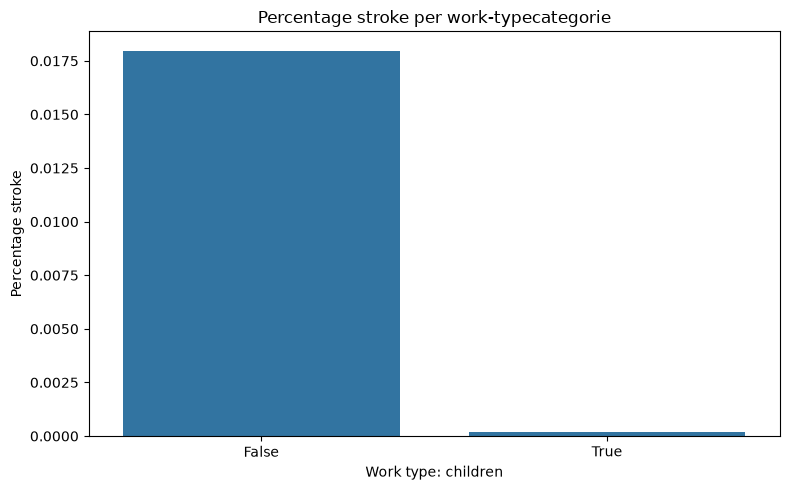

In [88]:
percent_smoking = (
    train.groupby("work_type_children")["stroke"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=percent_smoking, 
    x="work_type_children", 
    y="stroke")

plt.title("Percentage stroke per work-typecategorie")
plt.xlabel("Work type: children")
plt.ylabel("Percentage stroke")

plt.tight_layout()
plt.show()

**Conclusie**


De dummyvariabele `work_type_children` geeft aan of een persoon tot de categorie `children` behoort.

De visualisatie laat zien dat het percentage strokes bij kinderen vrijwel nul is, terwijl volwassenen een hoger percentage stroke hebben.

Dit verschil hangt waarschijnlijk sterk samen met leeftijd. De variabele kan daarom samen met andere kenmerken worden meegenomen in de verdere analyse.

### 1.5 belangrijkste bevindingen uit EDA

 Uit de EDA komen meerdere duidelijke patronen naar voren. 
 
 - **Leeftijd:** Oudere patiënten hebben in deze dataset relatief vaker een stroke. 
 - **Avg_glucose_level:** Hogere glucosewaarden lijken samen te hangen met een hoger percentage stroke.
 - **Heart disease:** Personen met hartziekten hebben relatief vaker een stroke. 
 - **Hypertension:** Ook bij hypertension is een verschil zichtbaar tussen de stroke- en niet-strokegroep.
 - **BMI:** De BMI-verdelingen van beide groepen overlappen grotendeels, waardoor geen sterk verschil zichtbaar is.

 Deze bevindingen geven richting aan de verdere preprocessing en het trainen van de machine-learningmodellen.

### 1.6 Data Standaardiseren


#### Waarom standaardiseren?

Standaardiseren betekent dat numerieke variabelen worden omgezet naar een vergelijkbare schaal. Hierbij krijgen de variabelen gemiddeld een waarde van 0 en een standaarddeviatie van 1.

Dit is vooral belangrijk voor modellen die gevoelig zijn voor verschillen in schaal, zoals:

- Logistic Regression
- K-Nearest Neighbors (KNN)
- Support Vector Machine (SVM)

In deze dataset hebben variabelen zoals `age`, `avg_glucose_level` en `bmi` verschillende schalen. Zonder standaardisatie kan een variabele met grotere numerieke waarden relatief meer invloed hebben op schaalgevoelige modellen.

Voor modellen zoals Decision Trees, Random Forest en Gradient Boosting is standaardiseren over het algemeen niet noodzakelijk.



In [89]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test= train_test_split(
    X, 
    y, 
    test_size= 0.2, 
    random_state= 42, 
    stratify= y)

In [90]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 2. Evaluatie 

### 2.1 Geef aan met welke “metrics”, voor deze vorm van machine learning, bepaalt kan worden hoe goed een model presteert.

Voor het vraagstuk “Predicting Stroke” wordt gebruikgemaakt van een classificatiemodel. Het doel van het model is om op basis van verschillende kenmerken van een persoon te voorspellen of deze persoon wel of geen stroke (beroerte) krijgt. De doelvariabele stroke bestaat uit twee mogelijke klassen: 0 betekent geen stroke en 1 betekent wel een stroke.

Om te bepalen hoe goed een classificatiemodel presteert, kunnen verschillende metrics worden gebruikt. Voor dit vraagstuk zijn de volgende metrics relevant:

-Accuracy

-Precision

-Recall

-F1-score

Voor het onderzoeken van deze metrics is gekozen voor het Logistic Regression-algoritme. De dataset is verdeeld in 80% trainingsdata en 20% validatiedata. De validatiedata wordt gebruikt om te beoordelen hoe goed het model voorspellingen maakt op data die het tijdens het trainen niet heeft gezien.

### Toon de uitkomsten op deze metrics aan de hand van een zelf te kiezen machine learning algoritm

In [91]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Model maken
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Model trainen
model.fit(X_train_scaled, y_train)

# Voorspellingen maken
y_pred = model.predict(X_test_scaled)

# Metrics berekenen
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

Accuracy: 0.7546944858420268
Precision: 0.04856641310708017
Recall: 0.8058252427184466
F1-score: 0.09161147902869757


### 2.2 Leg uit hoe iedere metric wordt berekend. Gebruik hierbij een confusion matrix. 

In [92]:
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)


Confusion Matrix:
[[4981 1626]
 [  20   83]]


De prestaties van het model kunnen worden weergegeven met behulp van een confusion matrix.
De vier waarden in de confusion matrix betekenen het volgende:

True Negative (TN) = 4977: het model voorspelde dat iemand geen stroke heeft en dat was correct.

False Positive (FP) = 1630: het model voorspelde dat iemand een stroke heeft, terwijl deze persoon daadwerkelijk geen stroke heeft.

False Negative (FN) = 18: het model voorspelde dat iemand geen stroke heeft, terwijl deze persoon daadwerkelijk wel een stroke heeft.

True Positive (TP) = 85: het model voorspelde dat iemand een stroke heeft en deze persoon heeft daadwerkelijk een stroke.

Deze vier waarden worden gebruikt om de verschillende metrics te berekenen.

1. Accuracy

Accuracy geeft aan welk percentage van alle voorspellingen correct is.

Formule:

$$
Accuracy = \frac{TP + TN}{TP + TN + FP + FN}
$$

Berekening:

$$
Accuracy = \frac{85 + 4977}{85 + 4977 + 1630 + 18}
$$

$$
Accuracy = \frac{5062}{6710} = 0.7544
$$

Resultaat:

Accuracy = 75,44%

Dit betekent dat het model in totaal 75,44% van de voorspellingen correct heeft gedaan.

2. Precision

Precision geeft aan hoe betrouwbaar de positieve voorspellingen van het model zijn.

In dit onderzoek betekent dit:

Van alle personen waarvan het model voorspelt dat zij een stroke hebben, hoeveel hebben daadwerkelijk een stroke?

Formule:

$$
Precision = \frac{TP}{TP + FP}
$$

Berekening:

$$
Precision = \frac{85}{85 + 1630}
$$

$$
Precision = \frac{85}{1715} = 0.0496
$$

Resultaat:

Precision = 4,96%

Dit betekent dat slechts 4,96% van de personen die door het model als “stroke” worden voorspeld, daadwerkelijk een stroke heeft.

3. Recall

Recall geeft aan hoeveel van de personen die daadwerkelijk een stroke hebben, correct door het model worden herkend.

Formule:

$$
Recall = \frac{TP}{TP + FN}
$$

Berekening:

$$
Recall = \frac{85}{85 + 18}
$$

$$
Recall = \frac{85}{103} = 0.8252
$$

Resultaat:

Recall = 82,52%

Dit betekent dat het model 82,52% van de personen die daadwerkelijk een stroke hebben correct heeft herkend.

4. F1-score

De F1-score combineert precision en recall in één metric. Hierdoor wordt rekening gehouden met zowel het aantal correcte positieve voorspellingen als het aantal daadwerkelijk gevonden stroke-gevallen.

Formule:

$$
F1 = 2 \times \frac{Precision \times Recall}{Precision + Recall}
$$

We gebruiken de eerder berekende waarden:

$$
Precision = 0.0496
$$

$$
Recall = 0.8252
$$

Berekening:

$$
F1 = 2 \times \frac{0.0496 \times 0.8252}{0.0496 + 0.8252}
$$

$$
F1 = 0.0935
$$

Resultaat:

F1-score = 9,35%

De F1-score is laag omdat de precision van het model erg laag is. Hoewel het model een hoge recall heeft, maakt het ook veel False Positive voorspellingen.

### 2.3 In de Kaggle competitie zie je dat er is gekozen voor de f1-score om te beoordelen hoe goed een model presteert. Leg uit waarom f1-score voor dit vraagstuk de beste maatstraf

in de Kaggle-competitie wordt de F1-score gebruikt om te bepalen hoe goed een model presteert. Voor dit vraagstuk is dat een geschikte keuze, omdat de dataset sterk imbalanced is.

In de dataset zijn er namelijk veel meer personen zonder stroke dan personen met een stroke. In onze validatieset waren er bijvoorbeeld 6607 personen zonder stroke en 103 personen met een stroke.

Wanneer alleen naar accuracy wordt gekeken, kan een model daardoor een relatief hoge score behalen door voornamelijk de meerderheidsgroep te voorspellen. Een model dat bijna iedereen als “geen stroke” voorspelt, kan bijvoorbeeld een hoge accuracy hebben, terwijl het model bijna geen personen met een daadwerkelijke stroke herkent.

Daarom zijn precision en recall belangrijker.

Recall is belangrijk omdat we zoveel mogelijk personen met een daadwerkelijke stroke willen herkennen. Een False Negative betekent namelijk dat iemand daadwerkelijk een stroke heeft, maar dat het model dit niet herkent.

Precision is ook belangrijk, omdat we willen voorkomen dat het model heel veel mensen onterecht als stroke voorspelt. Een hoge precision betekent dat een positieve voorspelling van het model relatief betrouwbaar is.

De F1-score combineert precision en recall in één metric. Hierdoor wordt een model niet alleen beloond voor het vinden van veel stroke-gevallen, maar wordt het ook afgestraft wanneer het daarbij heel veel False Positives maakt.

Dit is goed te zien in onze resultaten. Het model heeft een recall van 82,52%, maar een precision van slechts 4,96%. De F1-score komt daardoor uit op slechts 9,35%. De F1-score laat dus duidelijk zien dat het model wel veel stroke-gevallen vindt, maar tegelijkertijd veel fout-positieve voorspellingen maakt.

Daarom is de F1-score voor deze Kaggle-competitie een geschikte maatstaf. Accuracy zou bij deze sterk imbalanced dataset een te positief beeld kunnen geven, terwijl de F1-score rekening houdt met zowel precision als recall.

## 3.  Modelleren en uitleg modellen

### Voorwoord 

In deze opdracht trainen en evalueren we meerdere machine learning-modellen om de kans op een beroerte (stroke) te voorspellen. We werken met een imbalanced dataset waarin slechts ~1,5% van de patiënten daadwerkelijk een beroerte heeft gehad, waardoor standaard-aanpakken onbetrouwbare resultaten geven.

Voor elk model voeren we cross-validation en hyperparameter tuning uit via GridSearchCV met StratifiedKFold, zodat de klassenverdeling in iedere fold behouden blijft. De modellen die aan bod komen zijn K-Nearest Neighbors, Logistic Regression, SVM, Decision Tree, drie ensemble-methoden (Random Forest, Gradient Boosted Decision Trees en XGBoost) en tot slot een zelf samengesteld ensemble. Per model lichten we de werking toe, bespreken we relevante wiskundige formules, regularisatie en overfitting, en bepalen we de optimale hyperparameters. De beste configuratie van elk model wordt vervolgens toegepast op test.csv en de voorspellingen worden geüpload naar Kaggle om de prestaties objectief te vergelijken

### 3.1 De dataset is een “imbalanced dataset”. Leg uit waarom dit zo is.

Een dataset is imbalanced wanneer de klassen zeer ongelijk verdeeld zijn. In deze stroke-dataset:

Klasse 0 (geen beroerte): ≈ 98,5%

Klasse 1 (wel beroerte): ≈ 1,5%

De verhouding is dus ongeveer 64:1. Een model dat altijd "geen beroerte" voorspelt haalt al ~98,5% accuracy, maar vindt geen enkele patiënt met risico — precies wat je medisch gezien juist wél wilt detecteren.

### 3.1.2 Twee technieken voor de ongebalanceerde data
**1. Random undersampling.** Binnen iedere trainingsfold nemen we alle positieve voorbeelden en een willekeurige selectie negatieve voorbeelden. We vergelijken `sampling_strategy=0.1` (1 positief op 10 negatieven) en `0.25` (1 op 4). Zo krijgt de zeldzame klasse meer invloed. Een nadeel is dat we negatieve voorbeelden weglaten. We veranderen nooit de validatiefold of evaluatieset. Bron: imbalanced-learn developers (z.d.).

**2. Drempeloptimalisatie.** We vergelijken vooraf gekozen drempels van 0.10 tot en met 0.70. Een voorspelling wordt positief als de modelscore de gekozen drempel bereikt. Een lagere drempel geeft doorgaans meer positieve voorspellingen, met een afweging tussen recall en precision. We kiezen de drempel met CV-F1. Beide technieken worden op ieder model én het eigen ensemble toegepast. Na undersampling zijn scores niet automatisch gekalibreerde risico's in de oorspronkelijke bevolking. Bron: scikit-learn developers (z.d.-d).

We gebruiken geen SMOTE op deze dummyvariabelen: eenvoudige interpolatie zou tussenwaarden kunnen maken waar oorspronkelijk alleen 0 en 1 voorkomen. Standaardisatie gebeurt in een pipeline voor KNN, Logistic Regression en SVM, uitsluitend op de trainingsfold.
### 3.1.3 Aansluiting op de eerdere modellen
De vier eerdere modelsoorten (KNN, Logistic Regression, SVM en Decision Tree) worden hier opnieuw getuned voor één vergelijkbare eindtabel, samen met Random Forest, Gradient Boosting, XGBoost en ons eigen ensemble. Dit zijn **aanvullende vergelijkingsruns**, niet de eerder getoonde GridSearchCV-resultaten. De bestaande `grid_knn`, `grid_lr`, `grid_svm` en `grid_dt_balanced` worden niet gewijzigd. In deze aanvullende runs gebruiken alle acht modellen dezelfde rijen, kenmerken, folds, F1-maatstaf en twee technieken tegen klasse-ongelijkheid.

In de eerdere SVM-code wordt SMOTE vóór cross-validation uitgevoerd. Daardoor kan informatie tussen de folds terechtkomen. In dit aanvullende experiment vindt resampling alleen binnen de trainingsfold plaats. Ook het schalen gebeurt binnen de pipeline. De bestaande hoofdstukken blijven behouden, maar hun CV-scores zijn daarom niet zonder meer vergelijkbaar met deze eindtabel. De EDA en keuze om kolommen te verwijderen zijn al op de volledige dataset uitgevoerd; ook dat beperkt hoe onafhankelijk de evaluatie is (scikit-learn developers, z.d.-e).

Tekst en aanvullende code: OpenAI (2026), Prompt 1 en Prompt 2; zie paragraaf 4.6.

### 3.2 Pas onderstaande modellen toe en voer de onderstaande opdrachten uit.

### K-Nearest Neighbors (KNN)
**Werking**
KNN is een **instance-based** (lazy) algoritme. Om een nieuw punt $x$ te classificeren:
1. Bereken de **afstand** van $x$ tot álle trainingspunten.
2. Selecteer de $k$ dichtstbijzijnde buren.
3. Laat ze "stemmen" — de meerderheidsklasse wint.

**Afstandsmaten**

**Euclidean afstand (L2):**

$$
d(x,y) = \sqrt{\sum_{i=1}^{n}(x_i - y_i)^2}
$$

**Manhattan afstand (L1):**

$$
d(x,y) = \sum_{i=1}^{n}|x_i - y_i|
$$

Euclidean = rechte lijn ("hemelsbreed"), Manhattan = stadsblokken (alleen horizontaal/verticaal).

**Waarom is standaardisatie zo belangrijk?**
KNN werkt met afstanden. Een feature met grote schaal (bv. `avg_glucose_level` 50–300) **domineert** een feature met kleine schaal (bv. `hypertension` 0–1) volledig. Zonder standaardisatie wordt afstand feitelijk alleen bepaald door de grote feature. Met `StandardScaler` krijgt elke feature **gemiddelde 0 en standaarddeviatie 1**, waardoor alle features evenredig meetellen.

**Regularisatie bij KNN**
KNN heeft geen expliciete regularisatieterm, maar wel impliciete regularisatie:
- **Grotere $k$** → gladder beslisgrens → **minder overfitting** (hogere bias, lagere variantie)
- **Kleinere $k$** → zeer flexibel → **overfitting**
- `weights='distance'` geeft dichtere buren meer invloed → fijnere regularisatie

In [93]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
import pandas as pd



pipe_knn = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('knn', KNeighborsClassifier())
])

param_grid_knn = {
    'smote__k_neighbors': [3, 5],
    'knn__n_neighbors': [3, 5, 7, 11, 15, 21, 31],
    'knn__weights': ['uniform', 'distance'],
    'knn__metric': ['euclidean', 'manhattan']
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_knn = GridSearchCV(
    pipe_knn, param_grid_knn,
    scoring='f1', cv=cv, n_jobs=-1, verbose=1
)
grid_knn.fit(X_train, y_train)

print("Beste KNN params:", grid_knn.best_params_)
print("Beste CV F1-score:", grid_knn.best_score_)

Fitting 5 folds for each of 56 candidates, totalling 280 fits
Beste KNN params: {'knn__metric': 'manhattan', 'knn__n_neighbors': 3, 'knn__weights': 'uniform', 'smote__k_neighbors': 5}
Beste CV F1-score: 0.08142176111411696


### Logistic Regression

**Werking**

Logistic Regression berekent een lineaire combinatie van features en duwt het resultaat door een **sigmoid-functie** om een kans tussen 0 en 1 te krijgen:

$$
z = w_0 + w_1 x_1 + w_2 x_2 + \ldots + w_n x_n
$$

$$
\hat{y} = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

Als $\hat{y} \geq 0{,}5$ → klasse 1, anders klasse 0.

**Loss-functie: Binary Cross-Entropy**

$$
L(w) = -\frac{1}{m}\sum_{i=1}^{m}\Big[y_i \log(\hat{y}_i) + (1-y_i)\log(1-\hat{y}_i)\Big]
$$

**Toelichting:**

- Als $y_i = 1$ en $\hat{y}_i$ dichtbij 1 → $\log(\hat{y}_i) \approx 0$ → kleine loss ✓
- Als $y_i = 1$ en $\hat{y}_i$ dichtbij 0 → $\log(\hat{y}_i) \to -\infty$ → enorme loss ✗
- De loss straft **zelfverzekerd foute** voorspellingen extreem zwaar.

**Gradient Descent — rekenvoorbeeld**

Gradient descent zoekt het minimum van de loss door iteratief tegen de helling in te stappen:

$$
w_j := w_j - \eta \cdot \frac{\partial L}{\partial w_j}
$$

De gradient voor logistic regression is:

$$
\frac{\partial L}{\partial w_j} = \frac{1}{m}\sum_{i=1}^{m}(\hat{y}_i - y_i)\, x_{ij}
$$

**Rekenvoorbeeld (1 feature, 1 sample):** 

Stel $x = 2$, $y = 1$, $w = 0$, $b = 0$, learning rate $\eta = 0{,}1$.

1. **Forward:** $z = 0 \cdot 2 + 0 = 0$ → $\hat{y} = \sigma(0) = 0{,}5$
2. **Fout:** $\hat{y} - y = 0{,}5 - 1 = -0{,}5$
3. **Gradients:**

   - $\frac{\partial L}{\partial w} = -0{,}5 \cdot 2 = -1$
   - $\frac{\partial L}{\partial b} = -0{,}5$
4. **Update:**

   - $w := 0 - 0{,}1 \cdot (-1) = 0{,}1$
   - $b := 0 - 0{,}1 \cdot (-0{,}5) = 0{,}05$
5. **Nieuwe voorspelling:** $z = 0{,}1 \cdot 2 + 0{,}05 = 0{,}25$ → $\hat{y} = \sigma(0{,}25) \approx 0{,}562$

De voorspelling schuift op richting de echte waarde 1. Dit proces herhaalt zich duizenden iteraties tot de loss convergeert.

**Regularisatie bij Logistic Regression**

**L2 (Ridge):**

$$
L_{L2} = L(w) + \lambda \sum_{j=1}^{n} w_j^2
$$

Effect: krimpt alle gewichten richting 0 (maar nooit exact 0). Goed tegen multicollineariteit.

**L1 (Lasso):**

$$
L_{L1} = L(w) + \lambda \sum_{j=1}^{n} |w_j|
$$

Effect: duwt onbelangrijke gewichten **exact naar 0** → automatische feature selectie.

**Elastic Net:**

$$
L_{EN} = L(w) + \lambda \Big(\alpha \sum |w_j| + (1-\alpha) \sum w_j^2\Big)
$$

Combinatie van L1 en L2 — feature selectie plus stabiliteit.

In sklearn gebruik je $C = 1/\lambda$: **kleine C = sterke regularisatie**, grote C = zwakke regularisatie.

**Regularisatie vs. overfitting**

Overfitting ontstaat als het model te grote gewichten leert om de trainingsdata perfect te volgen (incl. ruis). Regularisatie **straft grote gewichten** in de loss, waardoor het model gedwongen wordt simpeler te blijven en beter generaliseert naar nieuwe data. Minder regularisatie (grote C) → risico op overfitting; sterke regularisatie (kleine C) → risico op underfitting. De juiste balans vind je met cross-validation.

In [94]:
from sklearn.linear_model import LogisticRegression

pipe_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('lr', LogisticRegression(max_iter=5000, class_weight='balanced'))
])

param_grid_lr = [
    {   # L1 en L2
        'lr__penalty': ['l1', 'l2'],
        'lr__C': [0.01, 0.1, 1, 10, 100],
        'lr__solver': ['liblinear', 'saga']
    },
    {   # Elastic Net
        'lr__penalty': ['elasticnet'],
        'lr__C': [0.01, 0.1, 1, 10],
        'lr__solver': ['saga'],
        'lr__l1_ratio': [0.2, 0.5, 0.8]
    }
]

grid_lr = GridSearchCV(
    pipe_lr, param_grid_lr,
    scoring='f1', cv=cv, n_jobs=-1, verbose=1
)
grid_lr.fit(X_train, y_train)

print("Beste Logistic Regression params:", grid_lr.best_params_)
print("Beste CV F1-score:", grid_lr.best_score_)

Fitting 5 folds for each of 32 candidates, totalling 160 fits


c:\Users\shari\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


Beste Logistic Regression params: {'lr__C': 0.01, 'lr__penalty': 'l2', 'lr__solver': 'saga'}
Beste CV F1-score: 0.09047961674190072


### Support Vector Machine (SVM)

### 3.3.1 Werking van het model

Een support vector machine (SVM) is een supervised machine-learningmodel dat gebruikt kan worden voor classificatie. In ons onderzoek wordt het model gebruikt om te voorspellen of een patiënt wel of geen stroke gaat krijgen. 

SVM probeert een scheiding te vinden tussen de twee klassen:
* klasse 0: geen stroke
* klasse 1: wel stroke

Het model zoekt een scheidingsgrens waarbij de afstand tussen de grens en de dichtsbijzijnde datapunten zo groot mogelijk is. Deze afstand heet de ***margin***. De datapunten die het dichts bij de scheidingsgres liggen, worden de support vectors genoemd. Deze punten bepalen voor een belangrijk deel waar de grens komt te liggen.

**Wiskundige formule**

Bij een lineaire SVM wordt de scheidingsgrens beschreven met:

$$
w^T x + b = 0
$$

hierbij geldt:
* x= de kenmerken van een patiënt, bijvoorbeeld leeftijd of de glucose level
* w= de gewichten die bepalen hoe de kenmerken meetellen
* b= de bias,die de positie van de scheidingsgrens beïnvloedt.

Om een nieuwe patiënt te classificeren, berekent het model:


$$
f(x) = 
w^T x + b = 0
$$

De voorspelling is vervolgens: 

$$
\hat{y} =
\begin{cases}
1 & \text{als } f(x) \ge 0 \\
0 & \text{als } f(x) < 0
\end{cases}
$$

De scheidingsgrens ligt bij f(x)=0. De twee grenzen van de margin liggen bij f(x)=−1 en f(x)=1, wanneer de SVM in de gebruikelijke canonieke vorm is geschreven.

**rekenvoorbeeld met een kleine deel van de dataset**
| index | age | avg_glucose_level | stroke |
| ----- | --- | ----------------- | ------ |
| 0     | 30.0| 63.60             | 0      |
| 1     | 75.0| 215.17            | 0      |
| 28    | 80.0| 259.63            | 1      |

We nemen een voorbeeld‑SVM met:

𝑤 = (0.03, 0.02), b= - 5

**Berekeningen beslisfunctie SVM**

Punt index 0:
$$
f(x_0) = 0.03 \cdot 30 + 0.02 \cdot 63.60 - 5 \\
= 0.9 + 1.272 - 5 \\
= -2.828
$$

Punt index 1:
$$
f(x_1) = 0.03 \cdot 75 + 0.02 \cdot 215.17 - 5 \\
= 2.25 + 4.3034 - 5 \\
= 1.5534
$$

Punt index 28:
$$
f(x_{28}) = 0.03 \cdot 80 + 0.02 \cdot 259.63 - 5 \\
= 2.4 + 5.1926 - 5 \\
= 2.5926
$$






### 3.3.2 Kernels en de kernel trick

Niet alle datasets kunnen goed worden gescheiden met een rechte lijn of een vlak. Soms is een gebogen scheidingsgrens nodig.

Een kernel is een functie waarmee SVM overeenkomsten tussen datapunten kan berekenen, zodat ook complexere scheidingsgrenzen mogelijk worden.

veelgebruikte kernels zijn: 

| kernel | werking |
| ------ | ------- |
| linear | gebruikt een lineaire scheidingsgrens |
| polynominaal | Kan kromme grenzen modelleren met polynomiale verbanden |
| RBF    | Kan complexe, niet-lineaire scheidingsgrenzen maken |
| sigmoid| Gebruikt een sigmoid-achtige overeenkomstfunctie |

Een veelgebruikte kernel is de RBF-kernel:
$$
K(x, z) = \exp(-\gamma \|x - z\|^2)
$$

Hierbij zijn x en z twee datapunten en is $\gamma$  een hyperparameter die bepaalt hoe sterk de overeenkomst afneemt naarmate punten verder uit elkaar liggen.
* een kleine $\gamma$ geeft een bredere invloed van datapunten en vaak een gladdere grens.
* een grote $\gamma$ geeft een beperkte invloed en kan een complexere grens opleveren, met meer kans op overfitting.

De kernel trick is nuttig wanneer de relatie tussen patiëntkenmerken en de doelvariabele niet goed met één lineaire grens kan worden beschreven.

### 3.3.3 Loss-functie 

SVM gebruikt bij de gebruikelijke soft-margin-classificatie de hinge loss. Deze loss straft verkeerde voorspellingen en voorspellingen die te dicht bij de scheidingsgrens liggen.

De hinge loss voor één datapunt is:
$$
L_i = \max(0,\; 1 - y_i f(x_i))
$$

Hierbij moet de doelvariabele $y_i$ de waarden −1 en +1 hebben. Dit is de gebruikelijke wiskundige notatie voor SVM.

De betekenis is:

Als $y_i f(x_i) \ge 1$, ligt het punt aan de juiste kant van de margin. De loss is 0.

Als $y_i f(x_i) < 1$, ligt het datapunt binnen de margin of aan de verkeerde kant van de grens. In dat geval is de loss groter dan nul en wordt deze berekend als $L_i = 1 - y_i f(x_i)$.

De gemiddelde Hinge loss kan worden geschreven als:
$$
L_{\text{hinge}} = \frac{1}{n} \sum_{i=1}^{n} \max(0,\; 1 - y_i f(x_i))
$$

**Rekenvoorbeeld**

Neem $y = +1$ en $f(x) = 0.4$:

$$
L = \max(0,\; 1 - (1)(0.4)) = 0.6
$$

Het datapunt ligt aan de juiste kant van de grens, maar binnen de margin.  
Daarom is de loss groter dan nul.


Als $f(x) = 1.5$, dan:

$$
L = \max(0,\; 1 - 1.5) = 0
$$

Het datapunt ligt nu correct buiten de margin en krijgt geen hinge loss.



Als $y = +1$ en $f(x) = -0.5$, dan:

$$
L = \max(0,\; 1 - (-0.5)) = 1.5
$$

Het datapunt is verkeerd geclassificeerd en krijgt een hogere loss.



Let op !

In onze dataset zijn de klassen oorspronkelijk 0 en 1.  
Voor de wiskundige berekening van de hinge loss wordt klasse 0 geïnterpreteerd als $-1$,  
terwijl klasse 1 gelijk blijft aan $+1$.  
Scikit-learn voert deze omzetting intern automatisch uit.

### 3.3.4 Regularisatie

Regularisatie voorkomt dat het model een onnodig complexe scheidingsgrens kiest die te sterk aansluit op de trainingsdata.

Bij SVM wordt de optimalisatie doorgaans beschreven als:

$$
\min_{w,b} \left( \frac{1}{2}\|w\|^2 + C \sum_{i=1}^{n} \max(0,\; 1 - y_i f(x_i)) \right)
$$

Hierbij zijn twee onderdelen belangrijk:

* De term $\frac{1}{2}\|w\|^2$ is de regularisatieterm. Deze stimuleert kleinere gewichten en daarmee een grotere margin.

* De som van de hinge losses straft punten die de margin niet goed respecteren.
* $C$ bepaalt hoe zwaar de fouten meetellen ten opzichte van regularisatie

De hyperparameter $C$ bepaalt dus de balans tussen een ruime margin en het beperken van trainingsfouten.

| Instelling | Effect | 
| ---------- | ------ |
| Hoge $C$   | Sterkere regularisatie; het model accepteert meer marge-overtredingen. Dit kan overfitting beperken, maar ook underfitting veroorzaken| 
| Lage $C$   | Minder sterke regularisatie; het model probeert trainingsfouten sterker te vermijden. Dit kan een complexere grens en meer overfitting opleveren |

Bij een RBF-kernel speelt ook $\gamma$ een rol bij de complexiteit van het model. Een hoge $\gamma$ kan een zeer flexibele grens opleveren. Dit is een extra reden om C en γ gezamenlijk te testen.

De keuze voor een lineaire of niet-lineaire kernel bepaalt bovendien welke soort scheidingsgrens het model kan leren. Dit is een modelkeuze, niet hetzelfde als de regularisatieterm zelf.

### 3.3.5 Hyperparameter tuning

In [95]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

pipe_svm = Pipeline([
    ('scaler', StandardScaler()),
    ('smote', SMOTE(random_state=42)),
    ('svm', SVC(class_weight='balanced'))
])

param_grid_svm = [
    {
        'svm__kernel': ['linear'],
        'svm__C': [0.01, 0.1, 1, 10]
    },
    {
        'svm__kernel': ['rbf'],
        'svm__C': [0.1, 1, 10],
        'svm__gamma': ['scale', 0.01, 0.1]
    }
]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_svm = GridSearchCV(
    pipe_svm,
    param_grid_svm,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_svm.fit(X_train, y_train)

print("Beste SVM-parameters:", grid_svm.best_params_)
print("Beste CV F1-score:", grid_svm.best_score_)

Fitting 5 folds for each of 13 candidates, totalling 65 fits
Beste SVM-parameters: {'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'}
Beste CV F1-score: 0.09071567844493729


**Uitkomsten SVM**

Tijdens de hyperparameteroptimalisatie zijn 13 verschillende parametercombinaties getest met 5‑fold cross‑validation (in totaal 65 fits).
Hieruit kwamen de volgende beste instellingen naar voren:
- Kernel: RBF
- C: 0.1
- Gamma: scale

De beste behaalde cross‑validation F1‑score is:

F1 = 0.0907

Deze score laat zien dat het SVM‑model met deze instellingen slechts beperkt onderscheid kan maken tussen patiënten met en zonder stroke binnen deze dataset.



### Decision Tree

### 3.4.1 Werking van het model

Een Decision Tree (beslisboom) is een supervised machine-learningmodel dat voorspellingen maakt door de data stapsgewijs op te splitsen in kleinere groepen.

In ons onderzoek voorspelt de beslisboom of een patiënt wel of geen beroerte heeft gehad. De boom begint bij een startpunt, de root node. Vervolgens worden kenmerken gebruikt om de patiënten in groepen te verdelen. Iedere splitsing is gebaseerd op een voorwaarde, bijvoorbeeld of de leeftijd groter is dan een bepaalde waarde.

De belangrijkste onderdelen zijn:
* De Root node: het beginpunt van de beslisboom
* Internal nodes: punten waarop een kenmerk wordt gebruikt om de data te splitsen.
* Branches: De mogelijke uitkomsten van een splitsing
* Leaf nodes: De eindpunten die de uiteindelijke voorspellingen geven

**Voorbeeld**
Stel dat het beslisboom begint bij de kenmerk *leeftijd*. De boom zoekt een splitsing die de groepen zo zuiver mogelijk een mogelijke eerste splitsing is:
- **Is age > 57?**
  - *Ja*: oudere patiënten. Hogere kans op een stroke.
  - *Nee*: jongere patiënten. Lagere kans op een stroke.

Binnen de groep waar Age > 58 geldt, kan de boom verder splitsen op bijvoorbeeld *Hypertension*:
- **Is Hpertension = 1?**
  - *Ja*: verhoogd risico
  - *Nee*: lager risico

Elke splitsing verkleint de groep en maakt de uiteindelijke voorspelling specifieker. De leaf nodes geven uiteindelijk aan of de patiënt wel of geen stroke zal hebben.




### 3.4.2 Criteria voor het maken van splitsing

Bij iedere splitsing probeert de beslisboom de data zo te verdelen dat de resulterende groepen zo zuiver mogelijk zijn. Een groep is zuiver wanneer de waarnemingen grotendeels of volledig tot dezelfde klasse behoren. 

Er zijn diverse criteria om de kwaliteit van een splitsing te beoordelen:

**1. Gini impurity** 

De gini impurity meet hoe gemengd de klasse in een groep zijn.
$$
Gini = 1 - \sum_{k=1}^{K} p_k^2
$$

Hierbij is $p_k$ het aandeel van klasse $k$ in de groep en $K$ het aantal klassen.

Voor twee klassen geldt:

$$
Gini = 1 - (p_0^2 + p_1^2)
$$

- Een Gini-waarde van 0 betekent dat de groep volledig zuiver is.
- Een hogere waarde betekent dat de groep meer gemengd is.

**Rekenvoorbeeld Gini-impurity** 


Stel dat we een groep patiënten hebben met twee klassen:
- Klasse 0: geen stroke
- Klasse 1: wel stroke

In deze groep geldt:
- 80% heeft **geen** stroke → $p_0 = 0.8$
- 20% heeft **wel** een stroke → $p_1 = 0.2$

De Gini-impurity voor deze groep is:

$$
Gini = 1 - (p_0^2 + p_1^2)
$$

Invullen geeft:

$$
Gini = 1 - (0.8^2 + 0.2^2)
    = 1 - (0.64 + 0.04)
    = 1 - 0.68
    = 0.32
$$

Dit betekent dat de groep **niet volledig zuiver** is: beide klassen komen voor, maar één klasse (geen stroke) is duidelijk dominant.

**2. Entropy en information gain**

Entropy meet niet alleen hoe gemengd de klassen zijn, maar vooral *hoeveel onzekerheid* er is in een groep.  
Hoe gelijker de klassen verdeeld zijn, hoe moeilijker het wordt om een juiste voorspelling te doen — en hoe hoger de entropy.

De formule is:

$$
H = - \sum_{k=1}^{K} p_k \log_2(p_k)
$$

- Als één klasse volledig domineert (bijv. $p_0 = 1$), is er **geen onzekerheid** → entropy = 0.  
- Als beide klassen even vaak voorkomen ($p_0 = 0.5$, $p_1 = 0.5$), is de **onzekerheid maximaal** → entropy is hoog.

**Rekenvoorbeeld**

Stel dat in een groep:
- 3 patiënten geen stroke hebben → $p_0 = 0.75$
- 1 patiënt wel een stroke heeft → $p_1 = 0.25$

Dan is de entropy:

$$
H = -0.75 \log_2(0.75) - 0.25 \log_2(0.25)
$$

$$
H \approx 0.811
$$

Dit betekent dat er *nog steeds onzekerheid* is: de groep is niet volledig zuiver, maar één klasse is wel duidelijk dominant.

Information Gain meet hoeveel de onzekerheid (entropy) afneemt door een splisting in de beslisboom.

De formule is:

$$
IG = H_{\text{ouder}} - \sum_{j=1}^{m} \frac{N_j}{N} H_j
$$

Hierbij geldt:
- $H_\text{ouder}$: de entropy vóór de splitsing
- $H_\text{j}$: de kindergroep van $j$
- $N_\text{j}$: het aantal patiënten in kindgroep j 
- $N$: het totale aantal patiënten vóór de splitsing

Een hoge Information Gain betekent dat de splitsing veel onzekerheid wegneemt,  
dus dat de groepen *zuiverder* worden en de beslisboom *betere voorspellingen* kan maken.

**Criteria in Scikit-learn**

In Scikit-learn kan het criterium voor het bepalen van splitsingen worden ingesteld met:

- `criterion='gini'`
- `criterion='entropy'`
- `criterion='log_loss'`

Deze opties bepalen hoe de onzuiverheid van een groep wordt berekend.  
In de praktijk leveren Gini en Entropy vaak vergelijkbare resultaten op.  
Welke het beste werkt, moet experimenteel worden bepaald.






### 3.4.3 Hyperparameters van de Dicision Tree

De kwaliteit van een beslisboom hangt niet alleen af van het gekozen splitsingscriterium, maar ook van de instellingen die bepalen hoe groot en complex de boom mag worden.

Belangrijke hyperparameters zijn:

| Hyperparameter | Effect en betekenis |
| -------------- | ------------------- |
| criterion      | Bepaalt hoe de kwaliteit van een spitsing wordt berekend |
| max_depth      | Beperkte de maximale diepte van een boom. Een lagere waarde maakt de boom eenvoudiger |
| min_samples_split | Bepaalt hoeveel waarnemingen minimaal nodig zijn om een knoop verder te splitsen |
| min_samples_leaf | bepaalt hoeveel waarnemingen minimaal in een eindknoop moeten zitten |
| max_leaf_nodes | Beperkt het maximale aantal eindknopen |
| ccp_alpha      | Bepaalt de sterkte van cost-complexity pruning. Een hogere waarde kan de boom kleiner maken |
| class_weight   | kan de minder voorkomende klasse zwaarder laten weewegen |

In [96]:
from sklearn.tree import DecisionTreeClassifier
pipe_dt_balanced = Pipeline([
    ("dt", DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

param_grid_dt = {
    "dt__criterion": ["gini", "entropy"],
    "dt__max_depth": [7, 10, 15, None],
    "dt__min_samples_split": [3, 10, 20],
    "dt__min_samples_leaf": [7, 10, 15],
    "dt__ccp_alpha": [0.0, 0.001, 0.01],
    "dt__class_weight": [None, "balanced"]
}

grid_dt_balanced = GridSearchCV(
    pipe_dt_balanced,
    param_grid_dt,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_dt_balanced.fit(X_train_scaled, y_train)

print("Beste parameters:", grid_dt_balanced.best_params_)
print("Beste CV F1-score:", grid_dt_balanced.best_score_)

Fitting 5 folds for each of 432 candidates, totalling 2160 fits
Beste parameters: {'dt__ccp_alpha': 0.01, 'dt__class_weight': 'balanced', 'dt__criterion': 'entropy', 'dt__max_depth': 7, 'dt__min_samples_leaf': 7, 'dt__min_samples_split': 3}
Beste CV F1-score: 0.09067090413041046


### 3.4.4 Pruning in de Decision Tree


Pruning is het proces waarbij een beslisboom bewust wordt ingekort om te voorkomen dat het model te complex wordt en gaat overfitten. Een boom die te diep groeit, kan zich aanpassen aan ruis of toevallige patronen in de trainingsdata. Door de boom te snoeien blijft alleen de structuur over die daadwerkelijk bijdraagt aan betere voorspellingen. 

In onze Decision Tree zijn er diverse vormen van pruning toegepast. De beste hyperparameters laten zien dat het model sterk is teruggesnoeid:

- **dt__max_depth = 7** 
Dit houdt dus in dat de boom maximaal 7 lagen diep mag worden, dit voorkomt dat de boom teveel splitsingen maakt en te specifiek wordt

- **dt__min_samples_split= 3**
Een node moet minimaal 3 samples bevatten voordat een nieuwe splitsing mag worden gemaakt. Dit voorkomt dat de boom splitst op heel kleine groepen.

- **dt__min_samples_leaf= 7**
Elke leaf node moet minimaal 7 samples bevatten. Dit is een vorm van sterke pruning: kleine, specifieke eindgroepen worden niet toegestaan.

- **dt__ccp_alpha= 0.01** 
Dit is expliciete cost‑complexity pruning. Een hogere waarde betekent dat meer takken worden verwijderd.  
De GridSearch kiest een relatief hoge waarde (0.01), wat aangeeft dat een sterk gesnoeide boom het beste generaliseert op deze dataset.

##### Relatie tussen pruning, overfitting en underfitting
- **Te weinig pruning -> overfiiting**
De boom wordt te diep en leert details die alleen in de trainingsdata voorkomen. Dit leidt tot hoge trainings-score 

- **Teveel pruning -> underfitting**
De boom wordt te simpel en mist belangrijke patronen in de data.
In onze resultaten zien we dit duidelijk:  
door de combinatie van max_depth=7, min_samples_leaf=7 en ccp_alpha=0.01 blijft de F1‑score steken rond **0.09**.  
De boom is zo sterk gesnoeid dat hij onvoldoende onderscheid kan maken tussen patiënten met en zonder beroerte.

**Conclusie**

Onze Decision Tree past meerdere vormen van pruning toe: beperking van de diepte, minimale samples per node, minimale samples per leaf en cost‑complexity pruning.  
De beste hyperparameters laten zien dat een sterk geprunde boom het beste generaliseert op deze dataset, maar dat de prestaties beperkt blijven door de complexiteit van het probleem en de sterke class imbalance.  
Dit verklaart waarom de F1‑score relatief laag blijft (0.09067).


**Vervolg op de eerdere modellen**

Voer eerst de eerdere cellen uit. Dit onderdeel gebruikt de bestaande datasets en splitsing. Alleen als XGBoost nog ontbreekt, voer je eenmalig `%pip install xgboost` uit in een aparte codecel.


In [97]:
from pathlib import Path
from time import perf_counter
import json
import platform
import sklearn
import imblearn
import xgboost
from IPython.display import display, Markdown
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline as SkPipeline
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, VotingClassifier
)
from sklearn.metrics import roc_auc_score, average_precision_score
from imblearn.under_sampling import RandomUnderSampler
from xgboost import XGBClassifier

SEED = 42
OUT = Path("resultaten_stroke")
OUT.mkdir(exist_ok=True)


required_names = (
    "train", "test", "sample", "X_train", "X_test", "y_train", "y_test", "cv"
)
missing_names = [name for name in required_names if name not in globals()]
if missing_names:
    raise RuntimeError(
        "Voer eerst de eerdere notebookcellen uit. Ontbreekt: "
        + ", ".join(missing_names)
    )

feature_columns = X_train.columns.drop("id", errors="ignore")
X_dev = X_train.loc[:, feature_columns].astype(float)
X_eval = X_test.loc[:, feature_columns].astype(float)
y_dev = y_train
y_eval = y_test
X_kaggle = test.loc[:, feature_columns].astype(float)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_train.index) | set(X_test.index) == set(train.index)
assert X_dev.columns.equals(X_eval.columns)
assert X_dev.columns.equals(X_kaggle.columns)
assert np.isfinite(X_dev.to_numpy()).all()
assert np.isfinite(X_eval.to_numpy()).all()
assert np.isfinite(X_kaggle.to_numpy()).all()
assert not X_dev.isna().any().any() and not X_eval.isna().any().any()
assert not X_kaggle.isna().any().any()
assert set(y.unique()) == {0, 1}
assert train["id"].is_unique and test["id"].is_unique
assert set(train["id"]).isdisjoint(test["id"])
assert sample["id"].is_unique and set(sample["id"]) == set(test["id"])
folds = list(cv.split(X_dev, y_dev))
thresholds = np.array([0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50, 0.60, 0.70])
print("Versies:", platform.python_version(), "sklearn", sklearn.__version__,
      "imblearn", imblearn.__version__, "xgboost", xgboost.__version__)
print("Aantal patiënten:", len(y), "| stroke:", int(y.sum()),
      "| percentage:", round(100 * y.mean(), 3))
print("Ontwikkelset:", len(y_dev), "| evaluatieset:", len(y_eval),
      "| positieve evaluatievoorbeelden:", int(y_eval.sum()))

Versies: 3.13.15 sklearn 1.9.0 imblearn 0.14.2 xgboost 3.4.1
Aantal patiënten: 33550 | stroke: 517 | percentage: 1.541
Ontwikkelset: 26840 | evaluatieset: 6710 | positieve evaluatievoorbeelden: 103


## 3.6 Ensembles
### 3.6.1 Random Forest
Random Forest traint meerdere beslisbomen op bootstrapsteekproeven: steekproeven met teruglegging. Dit heet **bagging**, oftewel bootstrap aggregation. Per splitsing wordt ook slechts een deel van de kenmerken overwogen. De voorspelde kansen van de bomen worden gemiddeld. Door meerdere verschillende bomen te combineren is het model doorgaans minder gevoelig voor overfitting dan één diepe boom.

Bomen zijn onafhankelijk te trainen en kunnen daarom **parallel** worden gebouwd. Meer bomen vragen meer rekentijd. We onderzoeken `max_depth` van 4 en 8 en `min_samples_leaf` van 5 en 20, met 120 bomen. Diepte en minimale bladgrootte beperken de complexiteit. Bron: scikit-learn developers (z.d.-a).

### 3.6.2 Gradient Boosted Decision Trees
Gradient Boosting bouwt bomen **sequentieel**. Elke nieuwe boom probeert de huidige loss verder te verlagen door de negatieve gradiënt te benaderen. Bij classificatie gebruiken we log-loss. Een eenvoudige weergave van het gecombineerde model is:

$$F_m(x)=F_{m-1}(x)+\eta h_m(x).$$

Hierbij is $h_m$ de nieuwe boom en $\eta$ de learning rate. Kleine stappen kunnen overfitting beperken, maar vragen vaak meer bomen. We vergelijken 60 en 120 bomen, diepte 1 en 2 en een vaste learning rate van 0.05. Omdat een volgende boom voortbouwt op eerdere bomen, kunnen deze boostingstappen niet onafhankelijk parallel worden getraind. De klassieke implementatie kan daardoor relatief veel trainingstijd vragen. Bron: scikit-learn developers (z.d.-b).

### 3.6.3 XGBoost
XGBoost is een geoptimaliseerde vorm van gradient boosting. Het gebruikt informatie over de eerste en tweede afgeleide van de loss en regularisatie om de boomcomplexiteit te beheersen. We gebruiken `tree_method='hist'`, die mogelijke splitsingen via histogrammen onderzoekt. Boostingrondes blijven **sequentieel**, maar berekeningen bij het bouwen van een boom kunnen **parallel** verlopen.

We vergelijken 80 en 160 bomen en `max_depth` van 2 en 4. `learning_rate=0.05`, `subsample=0.8`, `colsample_bytree=0.8` en `reg_lambda=1.0` staan vooraf vast. Sampling en regularisatie beperken de complexiteit. XGBoost kan efficiënter zijn dan klassieke Gradient Boosting; het is niet bij elke dataset en instelling sneller. Bron: XGBoost developers (z.d.).

### 3.6.4 Trainingstijd en parameters
Random Forest kan voordeel halen uit parallelle bomen; de twee boostingmethoden bouwen opeenvolgende bomen. Het aantal bomen, de diepte en de hardware beïnvloeden de werkelijke tijd. De tabel verderop toont zowel totale zoektijd als de tijd van één hertraining op de ontwikkelset. Zoekgrids verschillen in omvang, dus zoektijd is geen zuivere vergelijking van algoritmes.

## 3.7 Zelf samengesteld ensemble
Ons ensemble bevat **drie modellen**: Logistic Regression, Random Forest en Gradient Boosting. Logistic Regression geeft een relatief eenvoudige lineaire basis. Random Forest kan niet-lineaire verbanden en interacties opvangen. Gradient Boosting bouwt stapsgewijs een aanvullend boommodel. Verschillende modellen kunnen verschillende fouten maken, maar winst is niet gegarandeerd.

We kiezen **soft voting**: we middelen de voorspelde scores, eventueel met gewichten:

$$p_{ensemble}(x)=\frac{w_1p_{LR}(x)+w_2p_{RF}(x)+w_3p_{GB}(x)}{w_1+w_2+w_3}.$$

Bij hard voting stemt elk model alleen met een klasse. Soft voting bewaart meer informatie over de sterkte van de voorspelling en laat een gezamenlijke drempel toe. We vergelijken gewichten `(1,1,1)`, `(2,1,1)` en `(1,2,2)`. Daarnaast worden de undersamplingverhouding en drempel getuned. De basisinstellingen staan vooraf vast en worden hieronder volledig getoond; we nemen geen op dezelfde folds geselecteerde winnaars over als nieuwe onafhankelijke configuratie.

De modellen delen in elke fit dezelfde geresamplede trainingsset. Alleen de Logistic Regression-tak standaardiseert. De gezamenlijke score is door undersampling en ontbrekende kalibratie geen bewezen absolute risicokans. De meerwaarde van soft voting beoordelen we met F1 op gegevens met de oorspronkelijke verdeling. Bron: scikit-learn developers (z.d.-c).

In [98]:
def scaled_model(estimator):
    """Standaardiseer uitsluitend tijdens fit op de trainingsgegevens."""
    return SkPipeline([
        ("scaler", StandardScaler()), ("classifier", estimator)
    ])


voter = VotingClassifier(
    estimators=[
        ("lr", scaled_model(LogisticRegression(
            C=1.0, max_iter=2000, random_state=SEED
        ))),
        ("rf", RandomForestClassifier(
            n_estimators=120, max_depth=6, min_samples_leaf=10,
            random_state=SEED, n_jobs=1
        )),
        ("gb", GradientBoostingClassifier(
            n_estimators=80, max_depth=2, learning_rate=0.05,
            min_samples_leaf=10, random_state=SEED
        )),
    ],
    voting="soft", n_jobs=1
)
models = {
    "KNN": (scaled_model(KNeighborsClassifier()), {
        "model__classifier__n_neighbors": [11, 31],
        "model__classifier__metric": ["euclidean", "manhattan"],
    }),
    "Logistic Regression": (scaled_model(LogisticRegression(
        max_iter=2000, random_state=SEED
    )), {
        "model__classifier__C": [0.1, 1.0, 10.0],
    }),
    "SVM": (scaled_model(SVC(probability=True, random_state=SEED)), {
        "model__classifier__C": [0.1, 1.0],
        "model__classifier__kernel": ["linear", "rbf"],
    }),
    "Decision Tree": (DecisionTreeClassifier(random_state=SEED), {
        "model__max_depth": [3, 6], "model__min_samples_leaf": [10, 30],
    }),
    "Random Forest": (RandomForestClassifier(
        n_estimators=120, random_state=SEED, n_jobs=1
    ), {
        "model__max_depth": [4, 8], "model__min_samples_leaf": [5, 20],
    }),
    "Gradient Boosting": (GradientBoostingClassifier(
        learning_rate=0.05, min_samples_leaf=10, random_state=SEED
    ), {
        "model__n_estimators": [60, 120], "model__max_depth": [1, 2],
    }),
    "XGBoost": (XGBClassifier(
        learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
        reg_lambda=1.0, tree_method="hist", eval_metric="logloss",
        random_state=SEED, n_jobs=1
    ), {
        "model__n_estimators": [80, 160], "model__max_depth": [2, 4],
    }),
    "Eigen ensemble": (voter, {
        "model__weights": [(1, 1, 1), (2, 1, 1), (1, 2, 2)],
    }),
}


def build_pipeline(estimator):
    """Resampling vindt alleen plaats tijdens trainen, nooit bij predict."""
    return Pipeline([
        ("sampling", RandomUnderSampler(random_state=SEED)),
        ("model", clone(estimator)),
    ])


def tune_model(estimator, parameter_grid):
    """Zoek parameters en drempel met gemiddelde F1 over vijf folds."""
    grid = dict(parameter_grid)
    grid["sampling__sampling_strategy"] = [0.1, 0.25]
    history = []
    best = None
    start = perf_counter()
    for params in ParameterGrid(grid):
        fold_scores = []
        for train_idx, valid_idx in folds:
            fitted = build_pipeline(estimator).set_params(**params)
            fitted.fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
            probabilities = fitted.predict_proba(X_dev.iloc[valid_idx])[:, 1]
            scores = [
                f1_score(y_dev.iloc[valid_idx], probabilities >= threshold,
                         zero_division=0)
                for threshold in thresholds
            ]
            fold_scores.append(scores)
        fold_scores = np.asarray(fold_scores)
        means = fold_scores.mean(axis=0)
        for column, threshold in enumerate(thresholds):
            record = {
                "params": params, "threshold": float(threshold),
                "cv_f1": float(means[column]),
                "cv_sd": float(fold_scores[:, column].std(ddof=1)),
            }
            history.append(record)
            if best is None or record["cv_f1"] > best["cv_f1"]:
                best = record.copy()
    best["search_seconds"] = perf_counter() - start
    return best, history


best_settings = {}
search_history = {}
for name, (estimator, grid) in models.items():
    best_settings[name], search_history[name] = tune_model(estimator, grid)
    result = best_settings[name]
    print(f"{name}: CV-F1={result['cv_f1']:.4f}; "
          f"drempel={result['threshold']:.2f}; "
          f"zoektijd={result['search_seconds']:.1f} seconden", flush=True)

cv_winner = max(best_settings, key=lambda name: best_settings[name]["cv_f1"])
print("Vooraf geselecteerd op CV:", cv_winner)

KNN: CV-F1=0.1318; drempel=0.50; zoektijd=11.6 seconden
Logistic Regression: CV-F1=0.1532; drempel=0.60; zoektijd=1.8 seconden


c:\Users\shari\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\shari\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\shari\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(
c:\Users\shari\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\

SVM: CV-F1=0.1445; drempel=0.15; zoektijd=25.8 seconden
Decision Tree: CV-F1=0.1570; drempel=0.40; zoektijd=1.8 seconden
Random Forest: CV-F1=0.1546; drempel=0.30; zoektijd=11.6 seconden
Gradient Boosting: CV-F1=0.1607; drempel=0.30; zoektijd=7.9 seconden
XGBoost: CV-F1=0.1578; drempel=0.30; zoektijd=7.3 seconden
Eigen ensemble: CV-F1=0.1587; drempel=0.50; zoektijd=14.1 seconden
Vooraf geselecteerd op CV: Gradient Boosting


### 3.8 Geselecteerde instellingen en evaluatie op de bestaande testset
De onderstaande uitvoer vermeldt de geselecteerde parameters, samplingverhouding en drempel voor elk model. Vaste parameters staan bij de modeldefinities. CV-standaardafwijking beschrijft de spreiding tussen folds en is geen betrouwbaarheidsinterval. De evaluatieset wordt niet gebruikt om de instellingen te veranderen.

In [99]:
def evaluate_model(name, estimator, settings):
    """Fit eenmaal op de ontwikkelset en beoordeel op de evaluatieset."""
    fitted = build_pipeline(estimator).set_params(**settings["params"])
    start = perf_counter()
    fitted.fit(X_dev, y_dev)
    fit_seconds = perf_counter() - start
    probabilities = fitted.predict_proba(X_eval)[:, 1]
    predictions = (probabilities >= settings["threshold"]).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_eval, predictions, labels=[0, 1]
    ).ravel()
    metrics = {
        "Model": name,
        "CV F1": settings["cv_f1"], "CV SD": settings["cv_sd"],
        "Evaluatie F1": f1_score(y_eval, predictions, zero_division=0),
        "Precision": precision_score(y_eval, predictions, zero_division=0),
        "Recall": recall_score(y_eval, predictions, zero_division=0),
        "Accuracy": accuracy_score(y_eval, predictions),
        "ROC AUC": roc_auc_score(y_eval, probabilities),
        "Average precision": average_precision_score(y_eval, probabilities),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Fit seconden": fit_seconds,
        "Zoektijd seconden": settings["search_seconds"],
        "Drempel": settings["threshold"],
        "Kaggle F1": "Nog niet ingediend / score onbekend",
    }
    return fitted, metrics


fitted_models = {}
rows = []
for name, (estimator, _) in models.items():
    fitted_models[name], metrics = evaluate_model(
        name, estimator, best_settings[name]
    )
    rows.append(metrics)
results = pd.DataFrame(rows).set_index("Model")
for name, settings in best_settings.items():
    print(name, "\n", json.dumps(settings, indent=2), "\n")
display(results.round(4))
results.to_csv(OUT / "modelvergelijking.csv")
(OUT / "beste_parameters.json").write_text(
    json.dumps(best_settings, indent=2), encoding="utf-8"
)
(OUT / "zoekgeschiedenis.json").write_text(
    json.dumps(search_history, indent=2), encoding="utf-8"
)

c:\Users\shari\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


KNN 
 {
  "params": {
    "model__classifier__metric": "manhattan",
    "model__classifier__n_neighbors": 31,
    "sampling__sampling_strategy": 0.25
  },
  "threshold": 0.5,
  "cv_f1": 0.13178784212894348,
  "cv_sd": 0.025081918793264765,
  "search_seconds": 11.591128999833018
} 

Logistic Regression 
 {
  "params": {
    "model__classifier__C": 1.0,
    "sampling__sampling_strategy": 0.25
  },
  "threshold": 0.6,
  "cv_f1": 0.15321904996789434,
  "cv_sd": 0.042094725209209066,
  "search_seconds": 1.7593661001883447
} 

SVM 
 {
  "params": {
    "model__classifier__C": 1.0,
    "model__classifier__kernel": "rbf",
    "sampling__sampling_strategy": 0.1
  },
  "threshold": 0.15,
  "cv_f1": 0.14453978742840276,
  "cv_sd": 0.031961934535326114,
  "search_seconds": 25.786719299852848
} 

Decision Tree 
 {
  "params": {
    "model__max_depth": 3,
    "model__min_samples_leaf": 30,
    "sampling__sampling_strategy": 0.1
  },
  "threshold": 0.4,
  "cv_f1": 0.15698255336635153,
  "cv_sd": 0.04

,CV F1,CV SD,Evaluatie F1,Precision,Recall,Accuracy,ROC AUC,Average precision,TN,FP,FN,TP,Fit seconden,Zoektijd seconden,Drempel,Kaggle F1
Model,,,,,,,,,,,,,,,,
KNN,0.1318,0.0251,0.1466,0.1050,0.2427,0.9566,0.8285,0.0656,6394,213,78,25,0.0176,11.5911,0.50,Nog niet ingediend / score onbekend
Logistic Regression,0.1532,0.0421,0.1118,0.0822,0.1748,0.9574,0.8556,0.0690,6406,201,85,18,0.0195,1.7594,0.60,Nog niet ingediend / score onbekend
SVM,0.1445,0.0320,0.0930,0.0774,0.1165,0.9651,0.6860,0.0491,6464,143,91,12,1.4418,25.7867,0.15,Nog niet ingediend / score onbekend
Decision Tree,0.1570,0.0447,0.0923,0.0764,0.1165,0.9648,0.8207,0.0515,6462,145,91,12,0.0140,1.8442,0.40,Nog niet ingediend / score onbekend
Random Forest,0.1546,0.0223,0.1468,0.0961,0.3107,0.9446,0.8523,0.0670,6306,301,71,32,0.3384,11.5569,0.30,Nog niet ingediend / score onbekend
Gradient Boosting,0.1607,0.0189,0.1342,0.0872,0.2913,0.9423,0.8548,0.0669,6293,314,73,30,0.1952,7.8896,0.30,Nog niet ingediend / score onbekend
XGBoost,0.1578,0.0195,0.1117,0.0744,0.2233,0.9455,0.8542,0.0631,6321,286,80,23,0.1151,7.2733,0.30,Nog niet ingediend / score onbekend
Eigen ensemble,0.1587,0.0233,0.1270,0.0805,0.3010,0.9365,0.8562,0.0683,6253,354,72,31,0.3551,14.1269,0.50,Nog niet ingediend / score onbekend


134861

## 4 Conclusie en advies
### 4.1 Overzicht van alle modellen en ensembles
De tabel bevat alle acht modelsoorten uit opdracht 3, gemeten in de gezamenlijke vergelijkingsruns van paragraaf 3.5. De eerdere losse modelresultaten blijven in hun oorspronkelijke hoofdstukken staan. F1, precision en recall gaan over **stroke = 1**. De kolom CV F1 is gebruikt om instellingen te kiezen; Evaluatie F1 is berekend op de bestaande `X_test`-rijen. Het is dus geen Kaggle-score.

Vul in de volgende cel alleen echte Kaggle-F1-scores in van de acht bijbehorende `submission_*.csv`-bestanden uit dit onderdeel. Laat `None` staan zolang een score onbekend is. Voer de overzichtscel en de conclusie daarna opnieuw uit. Een eerdere inzending met een ander model of andere instellingen hoort niet bij deze scores.

Voor de definities van F1, precision en recall: scikit-learn developers (z.d.-f).


In [100]:
kaggle_scores = {
    "KNN": None,
    "Logistic Regression": None,
    "SVM": None,
    "Decision Tree": None,
    "Random Forest": None,
    "Gradient Boosting": None,
    "XGBoost": None,
    "Eigen ensemble": None,
}
for name, score in kaggle_scores.items():
    if score is None:
        results.loc[name, "Kaggle F1"] = "Nog niet ingevuld"
    else:
        if not 0 <= float(score) <= 1:
            raise ValueError(
                f"Kaggle F1 voor {name} moet tussen 0 en 1 liggen."
            )
        results.loc[name, "Kaggle F1"] = float(score)

comparison_columns = [
    "CV F1", "Evaluatie F1", "Precision", "Recall", "Kaggle F1"
]
display(results[comparison_columns].round(4))
results.to_csv(OUT / "modelvergelijking.csv")

,CV F1,Evaluatie F1,Precision,Recall,Kaggle F1
Model,,,,,
KNN,0.1318,0.1466,0.1050,0.2427,Nog niet ingevuld
Logistic Regression,0.1532,0.1118,0.0822,0.1748,Nog niet ingevuld
SVM,0.1445,0.0930,0.0774,0.1165,Nog niet ingevuld
Decision Tree,0.1570,0.0923,0.0764,0.1165,Nog niet ingevuld
Random Forest,0.1546,0.1468,0.0961,0.3107,Nog niet ingevuld
Gradient Boosting,0.1607,0.1342,0.0872,0.2913,Nog niet ingevuld
XGBoost,0.1578,0.1117,0.0744,0.2233,Nog niet ingevuld
Eigen ensemble,0.1587,0.1270,0.0805,0.3010,Nog niet ingevuld


### 4.2 Welk model presteert het beste
Voor de modelkeuze is vooraf de hoogste gemiddelde CV-F1 afgesproken. We tonen daarnaast welk model toevallig de hoogste evaluatie-F1 haalt. Als dit verschilt, passen we de keuze niet achteraf op diezelfde evaluatieset aan. Een nieuwe keuze zou een extra onafhankelijke toets vereisen. De onderstaande conclusie wordt rechtstreeks uit de berekende resultaten opgebouwd.

De scores en modelkeuze worden opnieuw berekend met de bestaande opgeschoonde data. Eerdere scores uit het losse notebook zijn daarom niet overgenomen als uitkomsten van deze versie. Zonder aanvullende toetsing concluderen we niet dat één algoritme overtuigend beter generaliseert.

In [101]:
eval_winner = results["Evaluatie F1"].idxmax()
selected = results.loc[cv_winner]
observed = results.loc[eval_winner]
settings = best_settings[cv_winner]
conclusion = (
    f"**Onze CV-keuze is {cv_winner}.** Dit model haalt binnen ons grid de "
    f"hoogste gemiddelde CV-F1: **{selected['CV F1']:.4f}**. "
    f"Op de bestaande evaluatieset is de F1 "
    f"**{selected['Evaluatie F1']:.4f}**, "
    f"de precision **{selected['Precision']:.4f}** en de recall "
    f"**{selected['Recall']:.4f}**. Het herkent **{int(selected['TP'])} van "
    f"{int(y_eval.sum())}** positieve gevallen, "
    f"mist **{int(selected['FN'])}** "
    f"en geeft **{int(selected['FP'])}** fout-positieve voorspellingen.\n\n"
    f"De hoogste waargenomen evaluatie-F1 is van **{eval_winner}** "
    f"met **{observed['Evaluatie F1']:.4f}**. Dit is een beschrijvende "
    f"vergelijking, geen extra tuningstap.\n\n"
    f"De geselecteerde instellingen voor {cv_winner} zijn "
    f"`{settings['params']}`, "
    f"met beslisdrempel **{settings['threshold']:.2f}**. "
    f"De overige vaste instellingen staan in de modeldefinities. "
    f"Een hoge accuracy alleen is onvoldoende: altijd klasse 0 voorspellen "
    f"haalt hier {1 - y_eval.mean():.2%} accuracy maar F1 = 0. "

)
known_kaggle = {
    name: float(score) for name, score in kaggle_scores.items()
    if score is not None
}
if known_kaggle:
    kaggle_winner = max(known_kaggle, key=known_kaggle.get)
    conclusion += (
        f"\n\nVan de ingevulde Kaggle-scores scoort **{kaggle_winner}** "
        f"het hoogst met **{known_kaggle[kaggle_winner]:.4f}**. "
        "Dit betreft alleen de inzendingen waarvan de score is ingevuld."
    )
else:
    conclusion += (
        "\n\nDe Kaggle-scores zijn nog onbekend; we kunnen nog geen "
        "Kaggle-winnaar of behaalde minimumscore bevestigen."
    )
conclusion += (
    "\n\nDe evaluatieset is eerder in dit notebook al bekeken. "
    "Deze uitslag is daarom een interne vergelijking en geen "
    "volledig onafhankelijke of klinische validatie."
)
display(Markdown(conclusion))
(OUT / "conclusie.txt").write_text(conclusion, encoding="utf-8")

**Onze CV-keuze is Gradient Boosting.** Dit model haalt binnen ons grid de hoogste gemiddelde CV-F1: **0.1607**. Op de bestaande evaluatieset is de F1 **0.1342**, de precision **0.0872** en de recall **0.2913**. Het herkent **30 van 103** positieve gevallen, mist **73** en geeft **314** fout-positieve voorspellingen.

De hoogste waargenomen evaluatie-F1 is van **Random Forest** met **0.1468**. Dit is een beschrijvende vergelijking, geen extra tuningstap.

De geselecteerde instellingen voor Gradient Boosting zijn `{'model__max_depth': 2, 'model__n_estimators': 60, 'sampling__sampling_strategy': 0.1}`, met beslisdrempel **0.30**. De overige vaste instellingen staan in de modeldefinities. Een hoge accuracy alleen is onvoldoende: altijd klasse 0 voorspellen haalt hier 98.46% accuracy maar F1 = 0. 

De Kaggle-scores zijn nog onbekend; we kunnen nog geen Kaggle-winnaar of behaalde minimumscore bevestigen.

De evaluatieset is eerder in dit notebook al bekeken. Deze uitslag is daarom een interne vergelijking en geen volledig onafhankelijke of klinische validatie.

1071

### 4.3 Overwegingen naast de modelprestaties
We nemen de volgende punten mee in ons advies voor dit project:

- **Gemiste positieve gevallen en foutmeldingen.** Recall beschrijft hoeveel positieve gevallen worden herkend; precision hoeveel positieve meldingen terecht zijn. Een hoge F1 geeft geen garantie dat de verhouding tussen die fouten praktisch acceptabel is. De gewenste afweging moet met zorgprofessionals worden vastgesteld.
- **Uitlegbaarheid.** Logistic Regression is eenvoudiger te beschrijven met coëfficiënten dan een ensemble van veel bomen. Bij bomen kunnen aanvullende verklaringen worden onderzocht. Een verband is geen bewijs van oorzaak en gevolg.
- **Betrouwbaarheid buiten deze dataset.** Een willekeurige interne splitsing bewijst niet dat prestaties gelijk blijven in een ander ziekenhuis, tijdvak of bij andere patiëntgroepen. We adviseren daarom eerst externe en tijdsgebonden evaluatie en controle per relevante subgroep.
- **Betekenis van de voorspelling.** Het meegeleverde Word-document omschrijft `stroke=1` als een patiënt die een infarct heeft gehad. Er staat geen expliciete toekomstige voorspeltermijn bij. Daarom kan onze classificatie niet zonder aanvullend onderzoek worden gepresenteerd als de kans op een infarct in bijvoorbeeld de komende vijf jaar. Ook moet worden vastgesteld of kenmerken vóór het infarct zijn gemeten.
- **Kalibratie en gebruik.** Door undersampling verandert de klasseverdeling tijdens trainen. Voor gebruik als risicopercentage moet kalibratie apart worden gecontroleerd met representatieve gegevens. Daarnaast zijn toegangsbeheer, verantwoord datagebruik, beheer en monitoring onderdeel van een eventuele vervolguitwerking.
- **Kosten en beheer.** Trainingstijd, voorspeltijd en eenvoud van onderhoud tellen mee. Een complexer model verdient alleen de voorkeur wanneer de meerwaarde voldoende overtuigend is.

Dit zijn projectmatige afwegingen en voorstellen voor vervolgonderzoek, geen vaststelling dat klinische validatie al is uitgevoerd.

### 4.4 Advies aan artsen
We adviseren **geen van deze modellen nu als zelfstandig klinisch beslissysteem**. Het op CV geselecteerde model uit paragraaf 4.2 is onze eerste kandidaat voor verder onderzoek, omdat het binnen ons vooraf vastgelegde experiment de beste F1-balans behaalt. Als de kandidaat een complex ensemble is, vergelijken we deze in vervolgonderzoek ook met Logistic Regression om te onderzoeken of de extra complexiteit voldoende oplevert. Als Logistic Regression zelf wint, is de eenvoud juist een aanvullend argument voor die kandidaat.

Voor eventuele ondersteuning van artsen moeten eerst de voorspeltermijn, het meetmoment van kenmerken, externe prestaties, kalibratie en de gevolgen van foutieve meldingen worden onderzocht. De arts blijft verantwoordelijk voor de beoordeling. De huidige resultaten onderbouwen alleen classificatie van het beschikbare label in deze dataset.

### 4.5 Voorspellingen voor Kaggle
Na de lokale evaluatie trainen we elk model opnieuw op alle gelabelde rijen, met uitsluitend de eerder gekozen instellingen. Vervolgens maken we voor `test.csv` een bestand met `id` en `stroke` (0 of 1). We koppelen op `id` om de volgorde van het voorbeeldbestand te behouden. De bestaande voorbeeldwaarden in `sample_submission.csv` zijn geen bekende testlabels en worden volledig vervangen.

De bestanden worden lokaal aangemaakt; er is vanuit dit notebook niets naar Kaggle geüpload. Upload de bestanden zelf, noteer de echte scores in `kaggle_scores` en voer de overzichtscel opnieuw uit. De vereiste Kaggle-F1 van minimaal 0.1 is pas bevestigd na een daadwerkelijke inzending. Een lokale F1 boven 0.1 garandeert dit niet.

In [102]:
submission_names = {
    "KNN": "knn", "Logistic Regression": "logistic_regression",
    "SVM": "svm", "Decision Tree": "decision_tree",
    "Random Forest": "random_forest", "Gradient Boosting": "gradient_boosting",
    "XGBoost": "xgboost", "Eigen ensemble": "eigen_ensemble",
}
for name, (estimator, _) in models.items():
    settings = best_settings[name]
    final_model = build_pipeline(estimator).set_params(**settings["params"])
    final_model.fit(
        train.loc[:, feature_columns].astype(float),
        train["stroke"].astype(int)
    )
    probabilities = final_model.predict_proba(X_kaggle)[:, 1]
    predictions = (probabilities >= settings["threshold"]).astype(int)
    by_id = pd.Series(predictions, index=test["id"])
    submission = sample[["id"]].copy()
    submission["stroke"] = submission["id"].map(by_id)
    assert submission["stroke"].notna().all()
    submission["stroke"] = submission["stroke"].astype(int)
    assert len(submission) == len(test)
    assert submission.columns.tolist() == ["id", "stroke"]
    assert set(submission["stroke"].unique()).issubset({0, 1})
    path = OUT / f"submission_{submission_names[name]}.csv"
    submission.to_csv(path, index=False)
    print(path.name, "| rijen:", len(submission),
          "| positief voorspeld:", int(submission["stroke"].sum()))

submission_knn.csv | rijen: 8388 | positief voorspeld: 352
submission_logistic_regression.csv | rijen: 8388 | positief voorspeld: 299


c:\Users\shari\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


submission_svm.csv | rijen: 8388 | positief voorspeld: 142
submission_decision_tree.csv | rijen: 8388 | positief voorspeld: 137
submission_random_forest.csv | rijen: 8388 | positief voorspeld: 403
submission_gradient_boosting.csv | rijen: 8388 | positief voorspeld: 356
submission_xgboost.csv | rijen: 8388 | positief voorspeld: 362
submission_eigen_ensemble.csv | rijen: 8388 | positief voorspeld: 473


### 4.6 Bronnen en verantwoording

- imbalanced-learn developers. (z.d.). *RandomUnderSampler*. https://imbalanced-learn.org/stable/references/generated/imblearn.under_sampling.RandomUnderSampler.html
- scikit-learn developers. (z.d.-a). *RandomForestClassifier*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html
- scikit-learn developers. (z.d.-b). *GradientBoostingClassifier*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.GradientBoostingClassifier.html
- scikit-learn developers. (z.d.-c). *VotingClassifier*. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html
- scikit-learn developers. (z.d.-d). *Tuning the decision threshold for class prediction*. https://scikit-learn.org/stable/modules/classification_threshold.html
- scikit-learn developers. (z.d.-e). *Common pitfalls and recommended practices*. https://scikit-learn.org/stable/common_pitfalls.html
- scikit-learn developers. (z.d.-f). *Metrics and scoring*. https://scikit-learn.org/stable/modules/model_evaluation.html
- XGBoost developers. (z.d.). *XGBoost parameters*. https://xgboost.readthedocs.io/en/stable/parameter.html

